# Recurrent Neural Network Models for Trajectory Generation

This notebook investigates how recurrent neural networks learn to generate two-dimensional movement trajectories from directional cues.

Two model variants are compared:

- **Standard model:** trained only to minimize trajectory prediction error.
- **Constrained model:** trained to minimize trajectory prediction error while also reducing correlations between direction-specific hidden-state representations.

The main analyses examine:

1. Synthetic trajectory generation.
2. Dataset construction and preprocessing.
3. Recurrent-network architecture.
4. Model training and validation.
5. Hidden-state correlations.
6. Principal-component representations of neural activity.
7. Predicted versus target trajectories.
8. The effect of task geometry and model constraints.

In [188]:
%matplotlib inline
import numpy as np, torch, torch.nn as nn, pickle, os, time
from torch.utils.data import Dataset, DataLoader, random_split
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

C_STD = "#2979ff"; C_CON = "#ff6d00"
np.set_printoptions(suppress=True, precision=3)

import os, glob, re
from matplotlib import gridspec
from itertools import combinations
N_IN = 3   # 3-channel 'paper' input (fixation + cos/sin target cue)

## Notebook Configuration

The Notebook is controlled by a central configuration block. The most important parameters are the number of movement directions, the angular separation between directions, the number of hidden units, the strength of the constrained-model penalty, and the training settings.

In the current configuration:

- Number of movement directions: `N_DIRS`
- Angular separation: `ANGLE` degrees
- Hidden units: `N_HID`
- Constrained penalty weight: `ALPHA_CON`
- Training seeds: `SEEDS`
- Trials per direction: `TRIALS_PER_DIR`

Changing these parameters and running the notebook again allows the effect of task complexity and representational constraints to be investigated systematically.


In [218]:
# =====================================================================
# Central experiment configuration
# Change values in this section, then use "Run All".
# ════════════════════════════════════════════════════════════════════════════

# ------------------------- Task geometry -----------------------------
N_DIRS = 5            # number of reach directions (maps notebook used 8; sweep used 2..7)
ANGLE = 10           # degrees between adjacent directions

# ----------------------------- Seeds ---------------------------------
SEEDS = [42]   # Random seeds used for independent training runs.

# ----------------------- Model and penalty ----------------------------
''' Weight of the correlation/decorrelation penalty in the Constrained model.
    Number of hidden units in the recurrent neural network. '''
ALPHA_CON   = 0.5          # Constrained penalty weight.
N_HID       = 300          # hidden units

# ---------------------------- Training -------------------------------
'''Learning rate used by the optimizer, Maximum gradient norm'''
LR          = 3e-7
CLIP        = 1.0
MAX_EPOCHS  = 8000         # Maximum number of complete passes through the training dataset.
PATIENCE    = 500          # Number of consecutive epochs allowed without sufficient validation andimprovement before early stopping is activated.
MIN_DELTA   = 1e-5         # Minimum decrease in validation loss required to count as an improvement.
PRINT_EVERY = 50           # Print training progress every 50 epochs.

# ------------------------- Data generation ---------------------------

TRIALS_PER_DIR = 256        # Number of trials retained for each direction.)
NOISE_MODE     = "absolute" # Determines how output noise is specified.
TARGET_NOISE   = 0.2      # absolute output-noise level (kept constant across N_DIRS)
SPLIT_SEED     = 42         # train/val/test split seed (fixed across model seeds)

# ----------------------------- Cache ---------------------------------
CACHE_DIR   = "."          # where the config-stamped model cache is written

# ------------------------- Safety check ------------------------------

assert all(s >= 1 for s in SEEDS), \
    "use seeds >= 1 (the RNN's `if seed is not None` is fine, but keep it clean)"
# Check that every random seed is at least 1.
# If a seed is invalid, Python stops here and displays the message.
print(
    f"CONFIG  "
    f"N_DIRS={N_DIRS}  "
    f"ANGLE={ANGLE}  "
    f"SEEDS={SEEDS}  "
    f"ALPHA_CON={ALPHA_CON}  "
    f"N_HID={N_HID}"
)

CONFIG  N_DIRS=5  ANGLE=10  SEEDS=[42]  ALPHA_CON=0.5  N_HID=300


## Synthetic Movement Trajectories

The dataset consists of synthetic two-dimensional trajectories. Each trajectory begins at the origin, moves upward, changes direction through an angular segment, and then remains at the target location.

For each trial, the model receives three input channels:

- A fixation signal during the initial hold period.
- The cosine of the target direction.
- The sine of the target direction.

The target output is a two-dimensional trajectory containing the time-dependent X and Y coordinates. Noise and augmentation are added to create multiple trials for each movement direction while preserving the underlying trajectory structure.


In [219]:
import numpy as np
from scipy.ndimage import gaussian_filter1d


def generate_diverging_trajectories(
    num_trajectories=8, total_angle_deg=120, d1=10, d2=5,
    n_straight=50, n_arc=50, n_hold_origin=20, n_hold_target=20,
    augmentation_factor=10, noise_level=0.02, plot=True,
    figsize=(18, 6), n_show=40, random_seed=42, scale=0.5, sigma=2, save_Fig=None):
    """
    Generate synthetic 2D trajectories with different movement directions.
    Returns
    -------
    inputs : ndarray
        Direction labels with shape (number_of_trials, 1).

    outputs : ndarray
        Two-dimensional trajectories with shape
        (number_of_trials, time_steps, 2).

    angles_deg : ndarray
        Angle assigned to each original trajectory.
    """

    np.random.seed(random_seed)
    angles_deg = np.linspace(-total_angle_deg/2, total_angle_deg/2, num_trajectories)
    trajectories = []
    for angle_deg in angles_deg:
        angle_rad = np.deg2rad(angle_deg)
        x0 = np.zeros(n_hold_origin); y0 = np.zeros(n_hold_origin)
        y1 = np.linspace(0, d1, n_straight); x1 = np.zeros_like(y1)
        t  = np.linspace(0, 1, n_arc)
        x2 = d2 * t * np.sin(angle_rad); y2 = d1 + d2 * t * np.cos(angle_rad)
        x3 = np.ones(n_hold_target) * x2[-1]; y3 = np.ones(n_hold_target) * y2[-1]
        trajectories.append((np.concatenate([x0, x1, x2, x3]),
                             np.concatenate([y0, y1, y2, y3])))
    X = np.array([tr[0] for tr in trajectories])
    Y = np.array([tr[1] for tr in trajectories])
    labels = np.arange(num_trajectories) * scale
    data_variance = noise_level * np.max(np.abs(X))
    for _ in range(augmentation_factor):
        X = np.concatenate((X, X + (data_variance * np.random.uniform(-1, 1, size=X.shape))), axis=0)
        Y = np.concatenate((Y, Y + (data_variance * np.random.uniform(-1, 1, size=Y.shape))), axis=0)
        labels = np.concatenate((labels, labels), axis=0)
    outputs = np.stack((X, Y), axis=2)
    inputs  = labels.reshape(-1, 1)
    outputs = gaussian_filter1d(outputs, sigma=sigma, axis=1)

    if plot:
        time = np.arange(outputs.shape[1])
        fig, axes = plt.subplots(1, 3, figsize=figsize, gridspec_kw={'width_ratios':[1,1,1]})
        ax = axes[0]
        for i in range(n_show): ax.plot(outputs[i,:,0], outputs[i,:,1], alpha=0.7)
        ax.set_aspect('equal'); ax.grid(True)
        ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_title("2D Trajectories")
        for k, lab in [(1, "X"), (2, "Y")]:
            ax = axes[k]
            for i in range(n_show): ax.plot(time, outputs[i,:,k-1], alpha=0.7)
            ax.axvline(n_hold_origin, color='k', linestyle='--')
            ax.axvline(outputs.shape[1]-n_hold_target, color='r', linestyle='--')
            ax.axvspan(0, n_hold_origin, color='blue', alpha=0.2, label='Sampling')
            ax.axvspan(n_hold_origin, outputs.shape[1]-n_hold_target, color='gray', alpha=0.2, label='Movement')
            ax.axvspan(outputs.shape[1]-n_hold_target, outputs.shape[1], color='green', alpha=0.2, label='Reward')
            ax.grid(True); ax.set_xlabel("Time"); ax.set_ylabel(lab)
            ax.set_title(f"{lab} evolution : {lab}(t)"); ax.legend()
        plt.tight_layout()
        if save_Fig is not None: plt.savefig(save_Fig, dpi=300, bbox_inches="tight")
        plt.show()
    print(f'INPUTS  : {inputs.shape}'); print(f'OUTPUTS : {outputs.shape}')
    return inputs, outputs, angles_deg

In [220]:
# =====================================================================
# Fixed trajectory geometry
# These values do not change when n_dirs or angle changes.
# =====================================================================

D1, D2   = 0, 10
TOTAL    = 100
N_HOLD_O = N_HOLD_T = int(TOTAL / 6)
N_ARC    = int(TOTAL * (0.1 * D2))
N_STRAIGHT = int(TOTAL * (0.1 * D1))     # == 0 when D1 == 0
SIGMA    = 3
SCALE    = 1.0
AUG      = 12

def build_synth(n, ang, data_seed=0):
    """One (n_dirs, angle) dataset -> stim (N,T,3), targ (N,T,2), dirs (N,),
    endpoint angles (deg), go-step. Noise held to TARGET_NOISE in absolute mode so
    changing N_DIRS does not secretly rescale the noise."""
    total_deg = ang * (n - 1)
    max_absX  = D2 * np.sin(np.deg2rad(total_deg / 2)) if total_deg > 0 else 1.0
    nl = (TARGET_NOISE / max_absX) if NOISE_MODE == "absolute" else 0.05

    inp, out, _ = generate_diverging_trajectories(
        num_trajectories=n, total_angle_deg=total_deg, d1=D1, d2=D2,
        n_hold_origin=N_HOLD_O, n_hold_target=N_HOLD_T,
        n_straight=N_STRAIGHT, n_arc=N_ARC,
        augmentation_factor=AUG, noise_level=nl, plot=False,
        scale=SCALE, sigma=SIGMA, random_seed=42 + data_seed)

    d_ids = np.rint(inp[:, 0] / SCALE).astype(np.int64)
    T     = out.shape[1]

    rng  = np.random.default_rng(0)
    keep = np.concatenate([rng.choice(np.where(d_ids == d)[0], TRIALS_PER_DIR,
                                      replace=False) for d in range(n)])
    rng.shuffle(keep)
    out, d_ids = out[keep], d_ids[keep]

    tpl   = np.stack([out[d_ids == d][:1].mean(0) for d in range(n)])
    theta = np.arctan2(tpl[:, -1, 1], tpl[:, -1, 0])

    stim = np.zeros((len(out), T, 3), dtype=np.float32)
    stim[:, :N_HOLD_O, 0] = 2.0 * 0.1                     # fixation, FIX_SCALE=0.1
    stim[:, :, 1] = (2.0 * np.cos(theta))[d_ids][:, None] # target cue cos
    stim[:, :, 2] = (2.0 * np.sin(theta))[d_ids][:, None] # target cue sin
    return stim, out.astype(np.float32), d_ids, np.rad2deg(theta), N_HOLD_O

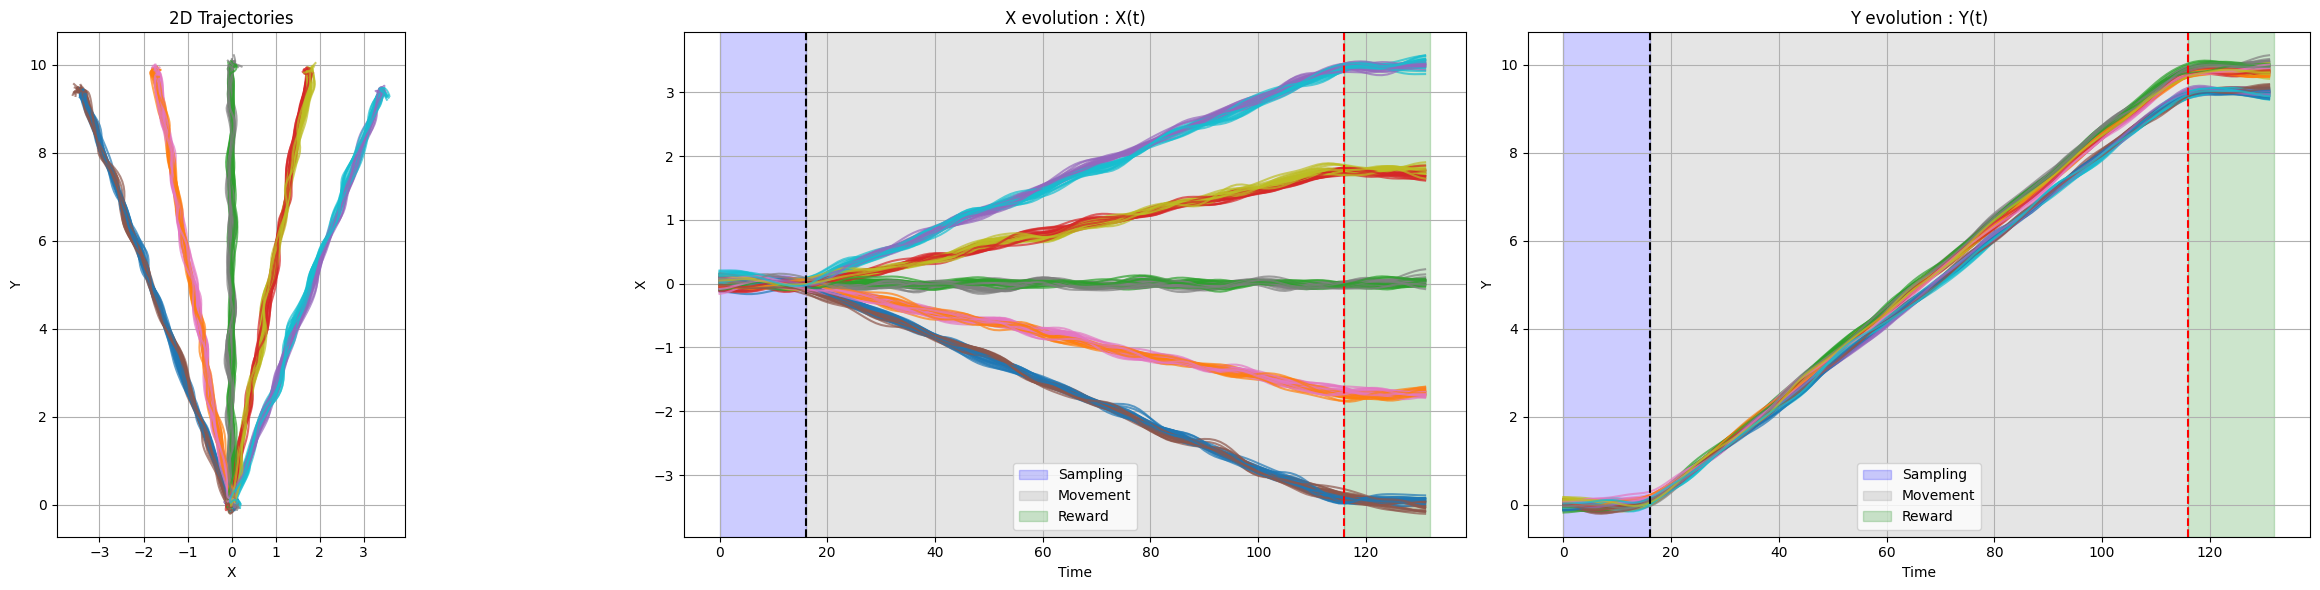

INPUTS  : (20480, 1)
OUTPUTS : (20480, 132, 2)

T_TOTAL = 132  (hold 16 | straight 0 | arc 100 | hold 16)
GO_STEP = 16
angles_deg (from +y axis) = [-20. -10.   0.  10.  20.]


In [221]:
##################################
######## Data Parameters #########
##################################
Num_Trajectories = 5
angle            = 10                       # <-- 10 deg spacing
total_angle_deg  = angle * (Num_Trajectories - 1)
total            = 100
n_hold_origin    = int(total/6)
n_hold_target    = int(total/6)
d1               = 0
d2               = 10
n_straight       = int(total * (0.1*d1))    # == 0 when d1 == 0
n_arc            = int(total * (0.1*d2))
SCALE            = 1.0
NOISE_LEVEL      = 0.05
AUG_FACTOR       = 12
SIGMA            = 3
DATA_SEED        = 42

INPUTS, OUTPUTS, angles = generate_diverging_trajectories(
        num_trajectories=Num_Trajectories,
        total_angle_deg=total_angle_deg,
        d1=d1, d2=d2,
        n_hold_origin=n_hold_origin, n_hold_target=n_hold_target,
        n_straight=n_straight, n_arc=n_arc,
        augmentation_factor=AUG_FACTOR,
        noise_level=NOISE_LEVEL,
        plot=True, figsize=(25, 6),
        scale=SCALE, n_show=200, sigma=SIGMA,
        random_seed=DATA_SEED,
    )

T_TOTAL = OUTPUTS.shape[1]
GO_STEP = n_hold_origin                     # movement onset index
print(f"\nT_TOTAL = {T_TOTAL}  (hold {n_hold_origin} | straight {n_straight} | arc {n_arc} | hold {n_hold_target})")
print(f"GO_STEP = {GO_STEP}")
print(f"angles_deg (from +y axis) = {np.round(angles, 2)}")

## Dataset Construction and Splitting

The generated trajectories are converted into a PyTorch dataset. Each sample contains an input sequence, a target trajectory, and an integer label identifying the movement direction.

The data are divided into training, validation, and test sets:

- The **training set** is used to optimize the network parameters.
- The **validation set** is used for monitoring generalization during training and for early stopping.
- The **test set** is reserved for evaluating the final trained model.

A fixed random seed is used for the split so that the comparison between model variants is reproducible.


In [222]:
class RNNDataset(Dataset):
    """
    PyTorch dataset for recurrent-network trajectory data.

    Each item contains:
        inputs     -> time-varying input signals
        targets    -> desired X-Y trajectories
        dir_labels -> integer direction label
    """
    def __init__(self, inputs, targets, dir_labels):
        self.inputs=torch.from_numpy(inputs).float()
        self.targets=torch.from_numpy(targets).float()
        self.dir_labels=torch.from_numpy(dir_labels).long()
    def __len__(self): return self.inputs.shape[0]
    def __getitem__(self, i): return self.inputs[i], self.targets[i], self.dir_labels[i]

def make_loaders(stim, targ, dirs, val_frac=0.1, test_frac=0.2, batch_size=64, seed=42):
    N=stim.shape[0]; rng=np.random.RandomState(seed); idx=rng.permutation(N)
    n_test=int(test_frac*N); tv=idx[:N-n_test]; te=idx[N-n_test:]
    ds_tv=RNNDataset(stim[tv],targ[tv],dirs[tv]); ds_te=RNNDataset(stim[te],targ[te],dirs[te])
    n_val=int(val_frac*len(ds_tv)); n_tr=len(ds_tv)-n_val
    g=torch.Generator().manual_seed(seed)
    tr_ds,val_ds=random_split(ds_tv,[n_tr,n_val],generator=g)
    return (DataLoader(tr_ds,batch_size=batch_size,shuffle=True),
            DataLoader(val_ds,batch_size=batch_size,shuffle=False),
            DataLoader(ds_te,batch_size=batch_size,shuffle=False), te)

## Recurrent Neural-Network Model

The model is a continuous-time-style recurrent neural network with a tanh activation function. At every time step, the hidden state is updated using the current input, recurrent feedback from the previous hidden state, and Gaussian noise during training.

The network contains:

- Input-to-hidden weights.
- Recurrent hidden-to-hidden weights.
- Hidden-to-output weights.
- A fixed recurrent connectivity mask.
- A leaky integration parameter controlled by `alpha`.

The hidden activity is used not only to generate the predicted trajectory but also to study how movement directions are represented internally.


In [223]:
class RNN(nn.Module):
    """
    Continuous-time-style recurrent neural network.

    The network receives an input sequence with shape:

        X: (T, B, n_in)

    where:

        T     = number of time steps
        B     = batch size
        n_in  = number of input channels

    It returns:

        O: (T, B, n_out)  predicted outputs
        H: (T, B, n_h)    hidden activity
    """
    def __init__(self, n_in, n_h, n_out, seed=None):
        super().__init__()
        if seed is not None: torch.manual_seed(seed)   
        self.alpha=0.2; self.noise=0.2
        self.W_ih=nn.Parameter(0.1*torch.randn(n_h,n_in)); self.b_ih=nn.Parameter(torch.zeros(n_h))
        self.W_hh=nn.Parameter(0.1*torch.randn(n_h,n_h));  self.b_hh=nn.Parameter(torch.zeros(n_h))
        self.W_out=nn.Parameter(0.1*torch.randn(n_out,n_h)); self.b_out=nn.Parameter(torch.zeros(n_out))
        self.register_buffer("mask", (torch.rand(n_h,n_h) < 0.8).float())
        self.n_h=n_h
    def forward(self, X):
        T,B,_=X.shape
        x = (torch.rand(B, self.n_h, device=X.device) - 0.5) * 0.1
        r = torch.tanh(x)
        H,O=[],[]
        for t in range(T):
            noise=self.noise*torch.randn_like(x) if self.training else 0.0
            dx=-x + r@(self.W_hh*self.mask).T + X[t]@self.W_ih.T + self.b_hh + self.b_ih + noise
            x=x+self.alpha*dx; r=torch.tanh(x)
            H.append(r); O.append(r@self.W_out.T + self.b_out)
        return torch.stack(O), torch.stack(H)

## Training Objective

The primary objective is the mean-squared error between the predicted and target trajectories. The loss is calculated after the initial fixation period so that the model is evaluated mainly on movement production.

For the constrained model, an additional correlation penalty is applied to the direction-specific hidden-state responses. This penalty discourages highly correlated representations of different movement directions.




In [ ]:
T0_LOSS = 0   # placeholder; the dataset cell sets this to GO_STEP

def mse_loss(out, tgt, t0=None):
    """
    Calculate the mean squared error after time point t0.
    Parameters
    ----------
    out : torch.Tensor
        Model predictions with shape (T, B, n_out).
    tgt : torch.Tensor
        Target trajectories with shape (T, B, n_out).
    t0 : int or None
        First time index included in the loss.
        If None, the global T0_LOSS value is used.
    Returns
    -------
    torch.Tensor
        Scalar loss value.
    """
    t0 = T0_LOSS if t0 is None else t0
    return (tgt[t0:]-out[t0:]).pow(2).sum() / (2*out.shape[1]*(out.shape[0]-t0))

def to_device(X, Y, dev):
    """
    Convert batch-major tensors to time-major tensors and move them
    to the selected device.

    Input shapes:
        X: (B, T, n_in)
        Y: (B, T, n_out)

    Output shapes:
        X: (T, B, n_in)
        Y: (T, B, n_out)
    """
    return X.permute(1,0,2).to(dev), Y.permute(1,0,2).to(dev)

@torch.no_grad()
def collect(model, loader, dev):
    """
    Run a model over a DataLoader without calculating gradients.
    Returns model loss, outputs, hidden activity, targets, and labels.
    """
    model.eval(); loss=0; outs=[]; hids=[]; tgts=[]; dls=[]
    for X,Y,D in loader:
        X,Y=to_device(X,Y,dev); o,h=model(X)
        loss+=mse_loss(o,Y).item()
        outs.append(o.cpu()); hids.append(h.cpu()); tgts.append(Y.cpu()); dls.append(D)
    return {"loss":loss/len(loader), "out":torch.cat(outs,1).numpy(),
            "hid":torch.cat(hids,1).numpy(), "tgt":torch.cat(tgts,1).numpy(),
            "dir":torch.cat(dls).numpy()}

def corr_penalty(hid, dirs):
    """
    Compute the sum of absolute pairwise correlations between the mean hidden activity
    Parameters
    ----------
    hid : torch.Tensor
        Hidden activity with shape (T, B, n_h).
    dirs : torch.Tensor
        Direction labels with shape (B,).
    Returns
    -------
    torch.Tensor
        Sum of absolute pairwise correlations.
    """
    ks=torch.unique(dirs)
    if ks.numel()<2: return hid.sum()*0.0
    rows=[hid[:,dirs==k,:].mean(1).reshape(-1) for k in ks]
    M=torch.stack(rows); Mc=M-M.mean(dim=1,keepdim=True)
    cov=Mc@Mc.t()
    d=torch.sqrt(torch.clamp(torch.diag(cov),min=1e-12))
    C=cov/(d[:,None]*d[None,:]+1e-8)
    iu=torch.triu_indices(C.shape[0],C.shape[1],offset=1)
    return C[iu[0],iu[1]].abs().sum()

## Direction-Specific Hidden-State Correlations

The correlation penalty measures the similarity between the hidden-state responses associated with different movement directions.

First, the hidden activity is averaged across trials belonging to the same direction. These direction-specific activity patterns are then centered and normalized. The absolute pairwise correlations are summed to produce the penalty.

A lower penalty indicates that the hidden representations for different directions are less correlated. This does not necessarily mean that the representations are completely independent, but it indicates reduced overlap in the measured activity patterns.


In [225]:
# ══════════════════════════════════════════════════════════════════════
#  Differentiable corr_penalty 
# ══════════════════════════════════════════════════════════════════════
def corr_penalty(hid, dirs, eps=1e-8):
    """
    Calculate the sum of absolute Pearson correlations between
    direction-specific hidden-state responses.
    Parameters
    ----------
    hid : torch.Tensor
        Hidden activity with shape:

            (T, B, H)

        T = number of time points
        B = number of trials
        H = number of hidden units
    dirs : torch.Tensor
        Direction label for each trial, shape:

            (B,)
    eps : float
        Small numerical constant used to avoid division by zero.
    Returns
    -------
    torch.Tensor
        Scalar penalty:
            sum of |Pearson correlation|
            over all unique direction pairs.
    """
    ks = torch.unique(dirs)
    if ks.numel() < 2:
        return hid.sum() * 0.0                      # zero, but keeps a grad path
    M = torch.stack([hid[:, dirs == k, :].mean(1).reshape(-1) for k in ks])  # (n_dirs, T*H)
    M = M - M.mean(dim=1, keepdim=True)             # center each row
    M = M / (M.norm(dim=1, keepdim=True) + eps)     # L2-normalize -> cosine == Pearson r
    C = M @ M.t()
    n = ks.numel()
    iu = torch.triu_indices(n, n, offset=1)
    return C[iu[0], iu[1]].abs().sum()


INPUTS  : (20480, 1)
OUTPUTS : (20480, 132, 2)
N_DIRS=5 ANGLE=10  stim (1280, 132, 3)  targ (1280, 132, 2)
T_TOTAL=132  GO_STEP=16  per-dir(train+val+test)=[256 256 256 256 256]
endpoint angles (deg): [110.2 100.5  89.5  80.7  69.5]
train 922  val 102  test 256


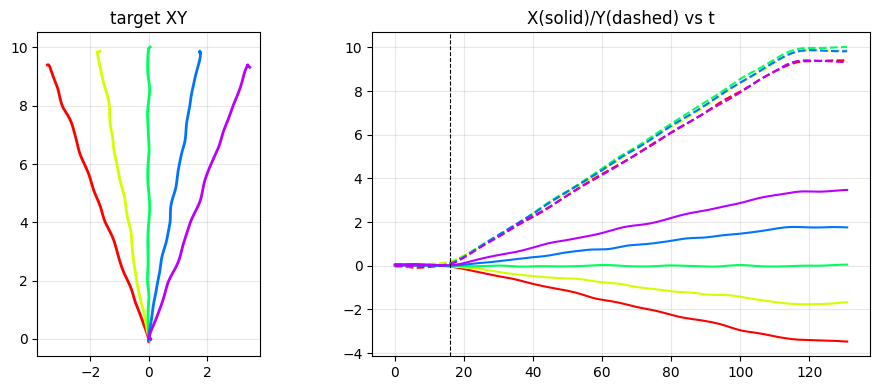

In [226]:
Num_Trajectories = N_DIRS
stim, targ, dirs, theta_deg, GO_STEP = build_synth(N_DIRS, ANGLE)
T_TOTAL = targ.shape[1]
T0_LOSS = GO_STEP                                  # score the movement epoch only
theta_rad = np.deg2rad(theta_deg)
colors_dirs = plt.cm.hsv(np.linspace(0, 1, Num_Trajectories, endpoint=False))

train_loader, val_loader, test_loader, test_idx = make_loaders(stim, targ, dirs, seed=SPLIT_SEED)
dirs_test = dirs[test_idx]

print(f"N_DIRS={N_DIRS} ANGLE={ANGLE}  stim {stim.shape}  targ {targ.shape}")
print(f"T_TOTAL={T_TOTAL}  GO_STEP={GO_STEP}  per-dir(train+val+test)={np.bincount(dirs)}")
print(f"endpoint angles (deg): {np.round(theta_deg,1)}")
print(f"train {len(train_loader.dataset)}  val {len(val_loader.dataset)}  test {len(test_loader.dataset)}")

# optional quick look at the target trajectories
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for d in range(Num_Trajectories):
    m = dirs_test == d
    mt = targ[test_idx][m].mean(0)
    ax[0].plot(mt[:, 0], mt[:, 1], color=colors_dirs[d], lw=2)
    ax[1].plot(np.arange(T_TOTAL), mt[:, 0], color=colors_dirs[d], lw=1.5)
    ax[1].plot(np.arange(T_TOTAL), mt[:, 1], color=colors_dirs[d], lw=1.5, ls='--')
ax[0].set_aspect('equal'); ax[0].set_title('target XY'); ax[0].grid(alpha=.3)
ax[1].axvline(GO_STEP, color='k', ls='--', lw=.8); ax[1].set_title('X(solid)/Y(dashed) vs t'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [227]:
DEV         = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CURVE_SEEDS = list(SEEDS)
REF_SEED    = CURVE_SEEDS[0]

# config-stamped cache: different CONFIGs never collide
CKPT = os.path.join(
    CACHE_DIR,
    f"combined_n{N_DIRS}_ang{ANGLE}_a{ALPHA_CON}_h{N_HID}_{len(CURVE_SEEDS)}seeds.pkl")

for _v in ["RNN","mse_loss","corr_penalty","collect","to_device",
           "train_loader","val_loader","test_loader","N_IN"]:
    if _v not in globals(): raise NameError(f"{_v} missing — run the Core + dataset cells first.")

store = pickle.load(open(CKPT,"rb")) if os.path.exists(CKPT) else {}
print(f"cache: {CKPT}")
print(f"{len(store)}/{2*len(CURVE_SEEDS)} runs cached | DEV={DEV} | ALPHA_CON={ALPHA_CON} "
      f"CLIP={CLIP} CAP={MAX_EPOCHS} PATIENCE={PATIENCE}")

def train_run(seed, use_pen, tag="", t0=None):
    """
    Train one RNN under one condition.

    Parameters
    ----------
    seed : int
        Random seed used to initialize the RNN.

    use_pen : bool
        If True, include the correlation penalty.
        If False, train using MSE only.

    tag : str
        Text label used in progress messages.

    t0 : float or None
        Start time used to display elapsed training time.

    Returns
    -------
    log : dict
        Training curves, best model state, stopping information,
        and final test loss.
    """
    m = RNN(N_IN, N_HID, 2, seed=seed).to(DEV)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    log = {"tr":[], "val":[], "pen":[]}
    best_val=np.inf; best_state=None; best_ep=0; wait=0
    for ep in range(MAX_EPOCHS):
        m.train(); tr=pen=nb=0
        for X,Y,D in train_loader:
            X,Y = to_device(X,Y,DEV); D=D.to(DEV)
            opt.zero_grad(); o,h = m(X)
            l = mse_loss(o,Y); p = corr_penalty(h,D)
            (l + ALPHA_CON*p if use_pen else l).backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), CLIP); opt.step()
            tr+=l.item(); pen+=p.item(); nb+=1
        vl = collect(m, val_loader, DEV)["loss"]
        log["tr"].append(tr/nb); log["pen"].append(pen/nb); log["val"].append(vl)
        if vl < best_val - MIN_DELTA:
            best_val=vl; best_ep=ep; wait=0
            best_state={k:v.cpu().clone() for k,v in m.state_dict().items()}
        else:
            wait+=1
        if ep % PRINT_EVERY == 0:
            el = f"  [{(time.time()-t0)/60:.1f}m]" if t0 else ""
            print(f"    {tag} ep {ep+1:5d}  MSE {tr/nb:.5f}  val {vl:.5f}  best {best_val:.5f}  sum|r| {pen/nb:6.2f}{el}")
        if wait >= PATIENCE:
            print(f"    {tag} early stop @ ep {ep+1}  (best {best_val:.5f} @ ep {best_ep+1})")
            break
    log["state"]=best_state; log["stopped_epoch"]=ep+1; log["best_epoch"]=best_ep+1
    m.load_state_dict({k:v.to(DEV) for k,v in best_state.items()})
    log["test"]=collect(m, test_loader, DEV)["loss"]
    return log

t0=time.time()
for seed in CURVE_SEEDS:
    for cond,use_pen in [("std",False),("con",True)]:
        if (seed,cond) in store:
            print(f"  seed {seed} {cond}: cached, skip"); continue
        print(f"\n=== seed {seed} {cond} (use_pen={use_pen}, alpha={ALPHA_CON if use_pen else 0}) ===")
        store[(seed,cond)] = train_run(seed, use_pen, tag=f"s{seed} {cond}", t0=t0)
        pickle.dump(store, open(CKPT,"wb"))
        print(f"  -> DONE stop@{store[(seed,cond)]['stopped_epoch']}  test {store[(seed,cond)]['test']:.5f}  "
              f"sum|r| {store[(seed,cond)]['pen'][-1]:.2f}")
print(f"\ndone — {len(store)} runs in {(time.time()-t0)/60:.1f} min")

cache: ./combined_n5_ang10_a0.5_h300_1seeds.pkl
0/2 runs cached | DEV=cpu | ALPHA_CON=0.5 CLIP=1.0 CAP=8000 PATIENCE=500

=== seed 42 std (use_pen=False, alpha=0) ===
    s42 std ep     1  MSE 18.89889  val 18.89060  best 18.89060  sum|r|   9.57  [0.0m]
    s42 std ep    51  MSE 12.83486  val 12.40050  best 12.40050  sum|r|   9.52  [0.8m]
    s42 std ep   101  MSE 9.24106  val 8.84155  best 8.84155  sum|r|   9.61  [1.5m]
    s42 std ep   151  MSE 6.89244  val 6.52506  best 6.52506  sum|r|   9.69  [2.3m]
    s42 std ep   201  MSE 5.18517  val 4.85588  best 4.85588  sum|r|   9.73  [3.0m]
    s42 std ep   251  MSE 3.92245  val 3.66408  best 3.66408  sum|r|   9.77  [3.7m]
    s42 std ep   301  MSE 2.99882  val 2.79228  best 2.79228  sum|r|   9.77  [4.5m]
    s42 std ep   351  MSE 2.33816  val 2.15119  best 2.15119  sum|r|   9.76  [5.2m]
    s42 std ep   401  MSE 1.84464  val 1.66898  best 1.66898  sum|r|   9.73  [6.0m]
    s42 std ep   451  MSE 1.46235  val 1.29377  best 1.29377  sum|r|   

In [228]:
def load_model(seed, cond):
    m=RNN(N_IN,N_HID,2,seed=seed)
    m.load_state_dict(store[(seed,cond)]["state"]); m.eval()
    return m
print("seeds available:", sorted({s for (s,_) in store}))

seeds available: [42]


## Test Performance and Trajectory Comparison

This section evaluates the standard and constrained models on the held-out test set.

First, the test mean-squared error is summarized across the seeds in `CURVE_SEEDS`. The mean provides the average prediction error, while the standard deviation shows the variability caused by different random initializations.

The first seed is then selected as a reference seed for visualization. For each model and movement direction, predictions and targets are averaged across test trials. Solid lines represent model outputs, whereas dashed lines represent the desired target trajectories.


test MSE (mean over seeds):
  std: 0.00876 +/- 0.00000
  con: 0.04016 +/- 0.00000


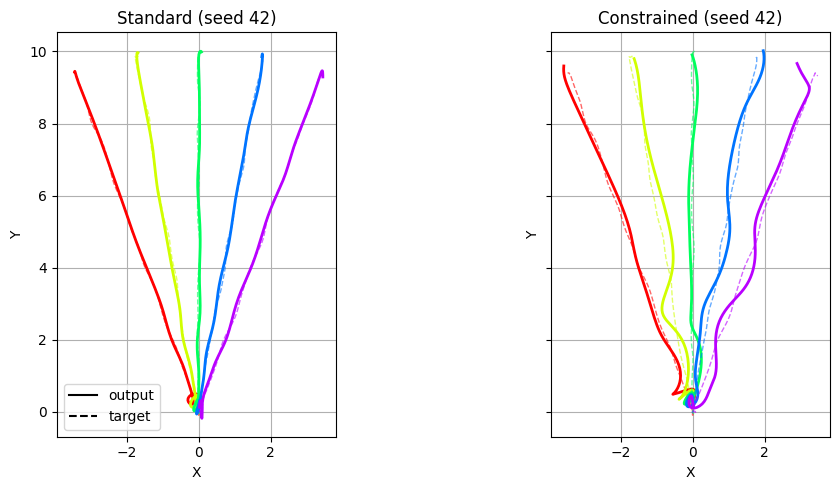

solid = model output, dashed = target. Constrained solids should reach the dashed endpoints.


In [229]:
REF_SEED = CURVE_SEEDS[0]

print("test MSE (mean over seeds):")
for cond in ("std","con"):
    vals=[store[(s,cond)]["test"] for s in CURVE_SEEDS]
    print(f"  {cond}: {np.mean(vals):.5f} +/- {np.std(vals):.5f}")

# trajectory overlay for the reference seed
cs = {c: collect(load_model(REF_SEED,c), test_loader, torch.device("cpu")) for c in ("std","con")}
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for a,(cond,title) in zip(ax, [("std","Standard"),("con","Constrained")]):
    C=cs[cond]
    for d in range(Num_Trajectories):
        m=C["dir"]==d
        mo=C["out"][:,m,:].mean(1); mt=C["tgt"][:,m,:].mean(1)
        a.plot(mo[:,0],mo[:,1],color=colors_dirs[d],lw=2)
        a.plot(mt[:,0],mt[:,1],color=colors_dirs[d],lw=1,ls='--',alpha=0.6)
    a.set_aspect('equal'); a.grid(True); a.set_title(f"{title} (seed {REF_SEED})")
    a.set_xlabel("X"); a.set_ylabel("Y")
ax[0].plot([],[],'k-',label='output'); ax[0].plot([],[],'k--',label='target'); ax[0].legend()
plt.tight_layout(); plt.show()
print("solid = model output, dashed = target. Constrained solids should reach the dashed endpoints.")

## Reference-Seed Hidden Activity and Trajectories

This figure compares the internal hidden activity and trajectory predictions of the Standard and Constrained RNNs for one reference seed. The heatmaps show normalized hidden-unit activity over time, with brighter colors indicating stronger activation; units are ordered by their peak activation time, and the dashed vertical line marks movement onset. The lower plots compare target trajectories with model outputs, while median |r| measures similarity between direction-specific hidden representations and MSE measures prediction error. Lower |r| indicates less correlated activity, and lower MSE indicates more accurate trajectories. Since only one seed is shown, 


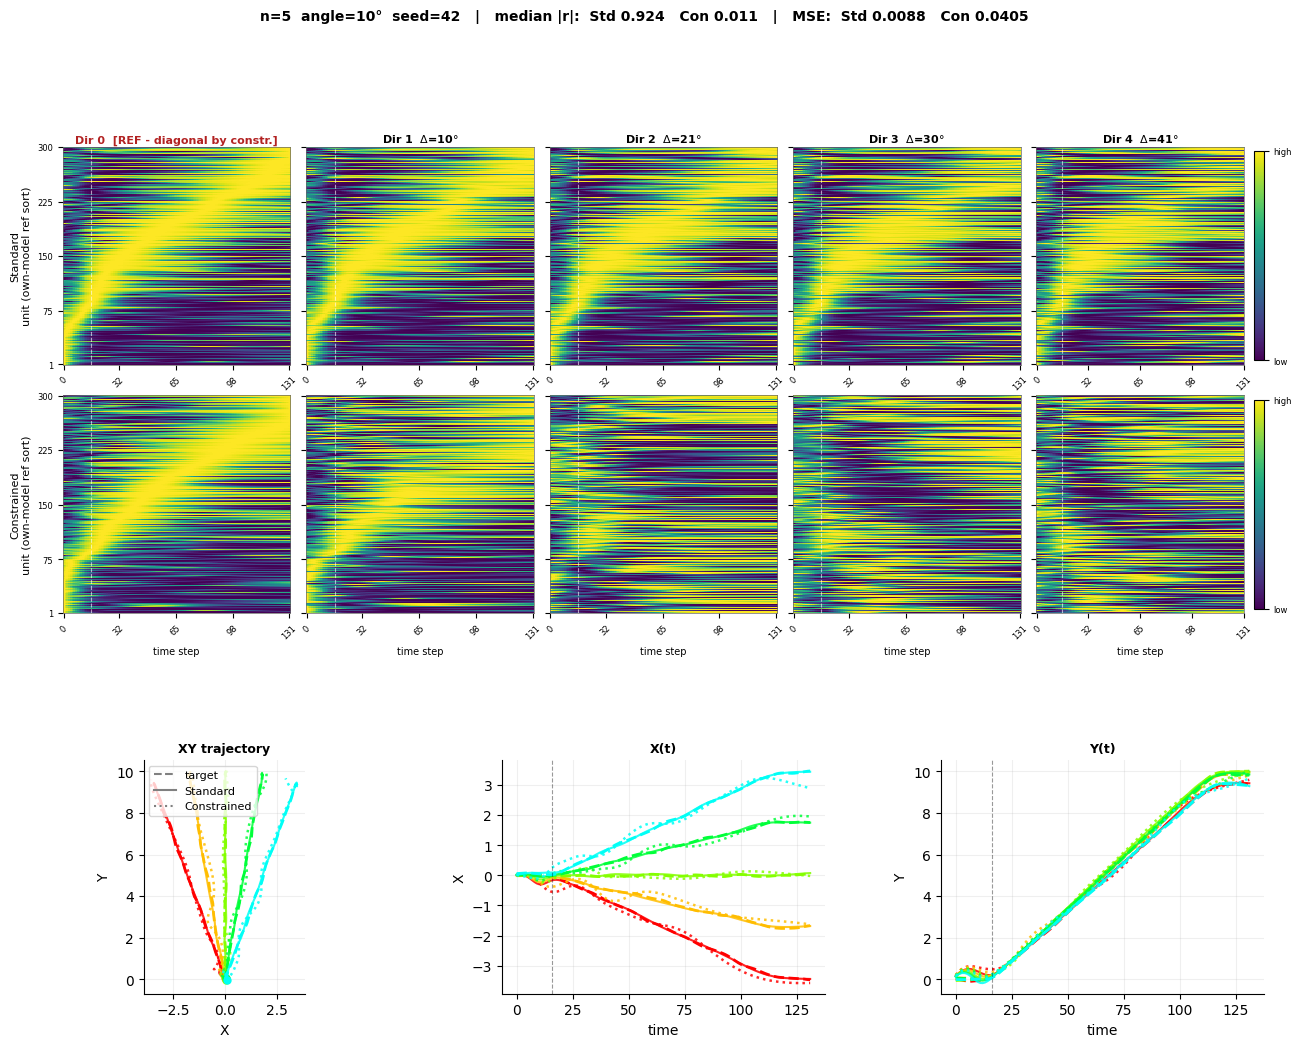

In [231]:
def _norm(m):
    """
    Min-max normalize each row independently.
    Parameters
    ----------
    m : ndarray
        Two-dimensional matrix with shape:

            (number_of_rows, number_of_columns)

        In this notebook, rows usually represent hidden units and
        columns represent time points.
    Returns
    -------
    ndarray
        Matrix in which every row is scaled approximately to [0, 1].
    """
    lo, hi = m.min(1, keepdims=True), m.max(1, keepdims=True)
    return (m - lo) / (hi - lo + 1e-8)

def _sort_ref(hid, mask):
    """
    Sort hidden units according to their peak time in a reference direction.
    Parameters
    ----------
    hid : ndarray
        Hidden activity with shape:

            (T, B, H)

        T = number of time points
        B = number of trials
        H = number of hidden units

    mask : ndarray of bool
        Boolean mask selecting trials belonging to the reference direction.
    Returns
    -------
    ndarray
        Hidden-unit indices sorted by their peak activation time.
    """
    return _norm(hid[:, mask, :].mean(1).T).argmax(1).argsort()

def heatmaps_ref_sorted(seed):
    """
    Create a diagnostic figure for one random seed.
    The figure contains:
    Top:
        Two rows of hidden-state heatmaps:
            row 1 -> Standard model
            row 2 -> Constrained model

        Each column represents one movement direction.

    Bottom:
        Three trajectory plots:
            1. X-Y trajectory
            2. X coordinate over time
            3. Y coordinate over time
    Hidden units are sorted separately for each model according to
    their peak time in the reference direction.
    """
    rs = cs["std"] if (seed==REF_SEED and "cs" in globals()) else collect(load_model(seed,"std"), test_loader, torch.device("cpu"))
    rc = cs["con"] if (seed==REF_SEED and "cs" in globals()) else collect(load_model(seed,"con"), test_loader, torch.device("cpu"))
    dte = rs["dir"]; ds = list(np.unique(dte)); ref, nc = ds[0], len(ds)
    go, T = GO_STEP, rs["hid"].shape[0]; n_h = rs["hid"].shape[2]
    theta = theta_deg
    ss, sc = _sort_ref(rs["hid"], dte==ref), _sort_ref(rc["hid"], dte==ref)

    def medr(hid):
        """
        Calculate the median absolute pairwise correlation between
        direction-specific hidden representations.

        Parameters
        ----------
        hid : ndarray
            Hidden activity with shape (T, B, H).

        Returns
        -------
        float
            Median absolute Pearson correlation across direction pairs.
        """
        M = np.array([hid[:, dte==d, :].mean(1).ravel() for d in ds])
        C = np.corrcoef(M); i, j = np.triu_indices(nc, k=1)
        return np.median(np.abs(C[i, j]))
    r_s, r_c = medr(rs["hid"]), medr(rc["hid"])
    m_s = ((rs["out"][go:]-rs["tgt"][go:])**2).mean(); m_c = ((rc["out"][go:]-rc["tgt"][go:])**2).mean()

    fig = plt.figure(figsize=(max(3.1*nc, 11), 11))
    gs  = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[2, 1], hspace=0.42)
    gh  = gridspec.GridSpecFromSubplotSpec(2, nc, subplot_spec=gs[0], hspace=0.14, wspace=0.07)
    gt  = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[1], wspace=0.36)
    cols = plt.cm.hsv(np.linspace(0, 1, 8, endpoint=False))

    for row, (r_, lab, srt) in enumerate([(rs,"Standard",ss), (rc,"Constrained",sc)]):
        for col, d in enumerate(ds):
            ax = fig.add_subplot(gh[row, col])
            im = ax.imshow(_norm(r_["hid"][:, dte==d, :].mean(1).T)[srt], aspect="auto",
                           cmap="viridis", vmin=0, vmax=1, origin="lower", interpolation="nearest")
            ax.axvline(go, color="white", lw=0.8, ls="--", alpha=0.6)
            xt = np.linspace(0, T-1, 5, dtype=int); ax.set_xticks(xt); ax.set_xticklabels(xt, fontsize=6, rotation=45)
            yt = np.linspace(0, n_h-1, 5, dtype=int); ax.set_yticks(yt)
            ax.set_yticklabels((yt+1) if col==0 else [""]*len(yt), fontsize=6)
            if row==1: ax.set_xlabel("time step", fontsize=7)
            if col==0: ax.set_ylabel(f"{lab}\nunit (own-model ref sort)", fontsize=8)
            if row==0:
                is_ref = d==ref
                tag = "  [REF - diagonal by constr.]" if is_ref else f"  $\\Delta$={abs(theta[col]-theta[0]):.0f}$\\degree$"
                ax.set_title(f"Dir {d}{tag}", fontsize=8, fontweight="bold", pad=3,
                             color="firebrick" if is_ref else "k")
            for sp in ax.spines.values(): sp.set_linewidth(0.5); sp.set_color("0.4")
            if col==nc-1:
                cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
                cb.set_ticks([0,1]); cb.set_ticklabels(["low","high"]); cb.ax.tick_params(labelsize=6)

    out_s, out_c = rs["out"].transpose(1,0,2), rc["out"].transpose(1,0,2)
    tgt, tax = rs["tgt"].transpose(1,0,2), np.arange(T)
    ax_xy = fig.add_subplot(gt[0,0]); ax_x = fig.add_subplot(gt[0,1]); ax_y = fig.add_subplot(gt[0,2])
    for i, d in enumerate(ds):
        m = dte==d; mt, ms_, mc = tgt[m].mean(0), out_s[m].mean(0), out_c[m].mean(0); c = cols[i % 8]
        ax_xy.plot(mt[:,0], mt[:,1], "--", color=c, lw=2.0); ax_xy.plot(ms_[:,0], ms_[:,1], "-", color=c, lw=1.5, alpha=.85)
        ax_xy.plot(mc[:,0], mc[:,1], ":", color=c, lw=1.8, alpha=.85); ax_xy.plot(mt[0,0], mt[0,1], "o", color=c, ms=5)
        for a_, j in [(ax_x,0),(ax_y,1)]:
            a_.plot(tax, mt[:,j], "--", color=c, lw=2.0); a_.plot(tax, ms_[:,j], "-", color=c, lw=1.5, alpha=.85)
            a_.plot(tax, mc[:,j], ":", color=c, lw=1.8, alpha=.85)
    for a_ in (ax_xy, ax_x, ax_y):
        a_.spines["top"].set_visible(False); a_.spines["right"].set_visible(False); a_.grid(alpha=0.2)
    for a_ in (ax_x, ax_y): a_.axvline(go, color="k", ls="--", lw=0.8, alpha=0.4)
    ax_xy.set_xlabel("X"); ax_xy.set_ylabel("Y"); ax_xy.set_aspect("equal"); ax_xy.set_title("XY trajectory", fontsize=9, fontweight="bold")
    ax_x.set_xlabel("time"); ax_x.set_ylabel("X"); ax_x.set_title("X(t)", fontsize=9, fontweight="bold")
    ax_y.set_xlabel("time"); ax_y.set_ylabel("Y"); ax_y.set_title("Y(t)", fontsize=9, fontweight="bold")
    ax_xy.legend(handles=[Line2D([0],[0],color="gray",ls="--",label="target"),
                          Line2D([0],[0],color="gray",ls="-", label="Standard"),
                          Line2D([0],[0],color="gray",ls=":", label="Constrained")], fontsize=8, loc="upper left")
    fig.suptitle(f"n={N_DIRS}  angle={ANGLE}\u00b0  seed={seed}   |   "
                 f"median |r|:  Std {r_s:.3f}   Con {r_c:.3f}   |   MSE:  Std {m_s:.4f}   Con {m_c:.4f}",
                 fontsize=10, fontweight="bold", y=1.005)
    plt.show(); plt.close(fig)

heatmaps_ref_sorted(REF_SEED)

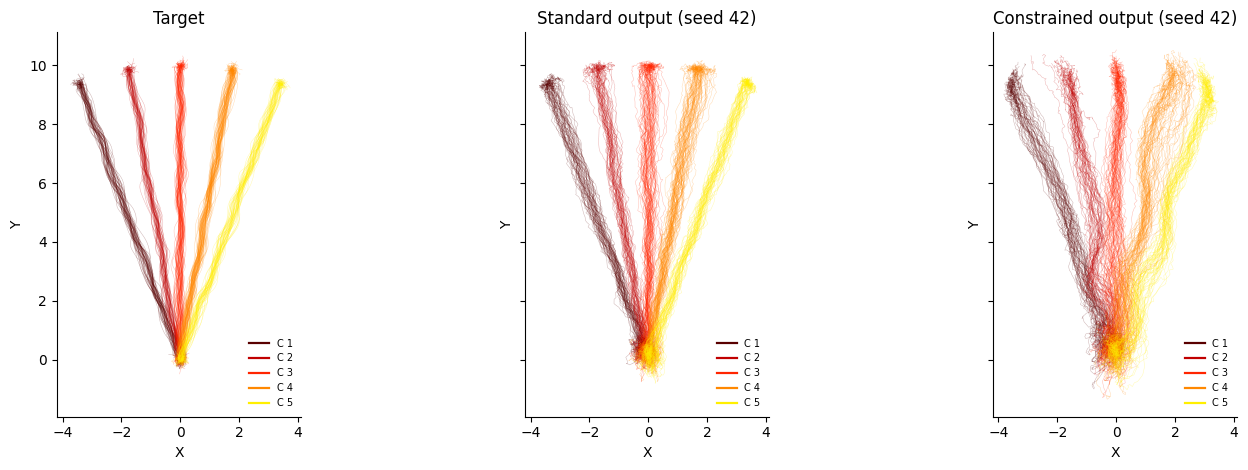

In [244]:
# ── Fig 3C/D-style single-trial fan overlay ──────────────────────────────
_need = [n for n in ("store","load_model","test_loader","Num_Trajectories",
                     "GO_STEP","REF_SEED") if n not in globals()]
if _need: raise NameError(f"run Core + dataset + train cells first (missing {_need})")

@torch.no_grad()
def collect_trials(model, loader, noise_on=True, seed=1):
    """Like collect(), but optionally rolls out WITH network noise so the
    single-trial spread looks like the paper. NEVER report MSE from this."""
    torch.manual_seed(seed)                    # x0 is unseeded in RNN.forward
    model.train() if noise_on else model.eval()
    outs, tgts, dls = [], [], []
    for X, Y, D in loader:
        X, Y = to_device(X, Y, torch.device("cpu"))
        o, _ = model(X)
        outs.append(o); tgts.append(Y); dls.append(D)
    model.eval()
    return {"out": torch.cat(outs,1).numpy(), "tgt": torch.cat(tgts,1).numpy(),
            "dir": torch.cat(dls).numpy()}

COLS = plt.get_cmap("hot")(np.linspace(0.12, 0.72, Num_Trajectories))

def fan_panel(ax, XY, dvec, title, n_show=100, lw=0.35, alpha=0.30, from_go=False):
    t0 = GO_STEP if from_go else 0
    rng = np.random.default_rng(0)
    for d in np.unique(dvec):
        idx = np.where(dvec == d)[0]
        if len(idx) > n_show: idx = rng.choice(idx, n_show, replace=False)
        seg = XY[t0:, idx, :]
        ax.plot(seg[:,:,0], seg[:,:,1], color=COLS[d], lw=lw, alpha=alpha,
                solid_capstyle="round")
    ax.set_title(title); ax.set_xlabel("X"); ax.set_ylabel("Y")
    ax.set_aspect("equal"); ax.spines[["top","right"]].set_visible(False)
    ax.legend(handles=[Line2D([],[],color=COLS[d],lw=1.6,label=f"C {d+1}")
                       for d in range(Num_Trajectories)],
              fontsize=7, frameon=False, loc="lower right")

ct = {c: collect_trials(load_model(REF_SEED, c), test_loader) for c in ("std","con")}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
fan_panel(ax[0], ct["std"]["tgt"], ct["std"]["dir"], "Target")
fan_panel(ax[1], ct["std"]["out"], ct["std"]["dir"], f"Standard output (seed {REF_SEED})")
fan_panel(ax[2], ct["con"]["out"], ct["con"]["dir"], f"Constrained output (seed {REF_SEED})")
fig.tight_layout(); display(fig); plt.close(fig)

## MSE Equivalence Test (check the name again)

This section tests whether the standard and constrained models have practically equivalent test MSE.

This procedure compares the paired MSE values across seeds using a predefined equivalence margin. Equivalence is supported when the 90% confidence interval for the MSE difference lies completely within this margin.

The boxplot shows the MSE distributions, with connecting lines representing paired results from the same seed. Because the number of seeds is small, the result should be interpreted cautiously.


/Users/kevin/work/hiwi/lib/python3.9/site-packages/numpy/_core/_methods.py:218: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/kevin/work/hiwi/lib/python3.9/site-packages/numpy/_core/_methods.py:210: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


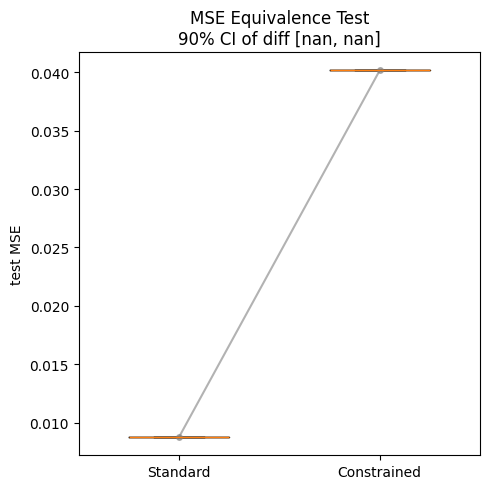

equivalence NOT established at this bound / N
N=1 seeds — MSE test is also underpowered here; scale to 8–10 before claiming equivalence.


In [243]:
from scipy.stats import t as _t

mse_std = np.array([store[(s, "std")]["test"] for s in CURVE_SEEDS])
mse_con = np.array([store[(s, "con")]["test"] for s in CURVE_SEEDS])

# --- MSE equivalence (a non-significant difference test is NOT equivalence) ---
# BOUND is the equivalence margin: the largest MSE gap you'd still call "same behaviour".

BOUND = 0.10 * mse_std.mean()          # placeholder (10% of Standard MSE) 
d = mse_con - mse_std; n = len(d); se = d.std(ddof=1) / np.sqrt(n)
p_lower = 1 - _t.cdf((d.mean() + BOUND) / se, n - 1)     # diff > -BOUND
p_upper = _t.cdf((d.mean() - BOUND) / se, n - 1)         # diff < +BOUND
p_tost = max(p_lower, p_upper)
ci = (d.mean() - _t.ppf(0.95, n-1)*se, d.mean() + _t.ppf(0.95, n-1)*se)   # 90% CI: matches TOST at alpha=0.05

fig, ax = plt.subplots(figsize=(5, 5))
ax.boxplot([mse_std, mse_con], tick_labels=["Standard", "Constrained"], widths=.5)
for a, b in zip(mse_std, mse_con):
    ax.plot([1, 2], [a, b], color="gray", alpha=.6, marker="o", ms=4)
ax.set_ylabel("test MSE")
ax.set_title(f"MSE Equivalence Test\n"
             f"90% CI of diff [{ci[0]:.4f}, {ci[1]:.4f}]")
plt.tight_layout(); plt.show()
print("equivalence supported" if (p_tost < 0.05 and ci[0] > -BOUND and ci[1] < BOUND)
      else "equivalence NOT established at this bound / N")
print(f"N={n} seeds — MSE test is also underpowered here; scale to 8–10 before claiming equivalence.")

## PCA Explained-Variance Analysis

This section applies principal-component analysis to the hidden activity of the standard and constrained models.

The plot shows how much variance is explained cumulatively as more principal components are included. The shaded regions represent variability across random seeds.

The number of components required to reach 90% explained variance is printed for each model. Fewer components indicate a more compact representation of the hidden activity.


/Users/kevin/work/hiwi/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/kevin/work/hiwi/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/kevin/work/hiwi/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/kevin/work/hiwi/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/kevin/work/hiwi/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/kevin/work/hiwi/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X


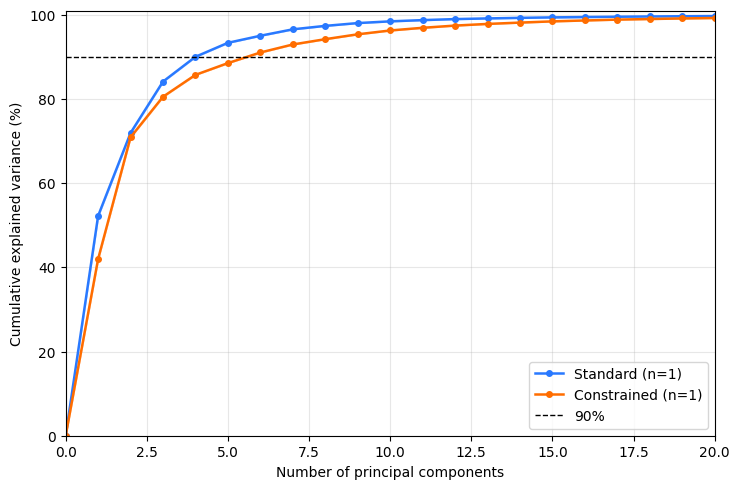

Standard: PCs to reach 90% variance = 4
Constrained: PCs to reach 90% variance = 6


In [234]:
def cum_var_curve(seed, cond, max_pc=10):
    """
    Calculate the cumulative explained-variance curve for one model.

    Parameters
    ----------
    seed : int
        Random seed identifying the trained model.

    cond : str
        Model condition:
            "std" -> Standard model
            "con" -> Constrained model

    max_pc : int
        Maximum number of principal components to calculate.

    Returns
    -------
    ndarray
        Cumulative explained variance in percent.

        The first element is 0%, representing zero components.
        The remaining elements correspond to PC1, PC2, ..., PCk.
    """
    C=cs[cond] if (cond in cs and seed==REF_SEED) else collect(load_model(seed,cond), test_loader, torch.device("cpu"))
    H=C["hid"]                                    # (T, B, N)
    Xmat=H.transpose(1,0,2).reshape(-1, H.shape[2])  # (T*B, N)
    k=min(max_pc, Xmat.shape[1])
    p=PCA(n_components=k).fit(Xmat)
    return np.concatenate([[0.0], np.cumsum(p.explained_variance_ratio_)*100])

MAX_PC=20
curves_pca={c: np.stack([cum_var_curve(s,c,MAX_PC) for s in CURVE_SEEDS]) for c in ("std","con")}
xs=np.arange(MAX_PC+1)

fig, ax = plt.subplots(figsize=(7.5,5))
for cond,color,lab in [("std",C_STD,"Standard"),("con",C_CON,"Constrained")]:
    M=curves_pca[cond]; mu=M.mean(0); sd=M.std(0)
    ax.plot(xs, mu, color=color, marker='o', ms=4, lw=1.8, label=f"{lab} (n={len(CURVE_SEEDS)})")
    ax.fill_between(xs, mu-sd, mu+sd, color=color, alpha=0.2)
ax.axhline(90, color='k', ls='--', lw=1, label='90%')
ax.set_xlabel("Number of principal components"); ax.set_ylabel("Cumulative explained variance (%)")
ax.set_xlim(0, MAX_PC); ax.set_ylim(0, 101); ax.legend(loc="lower right"); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

for cond,lab in [("std","Standard"),("con","Constrained")]:
    mu=curves_pca[cond].mean(0)
    pc90=int(np.argmax(mu>=90)) if (mu>=90).any() else None
    print(f"{lab}: PCs to reach 90% variance = {pc90}")

## Hidden-State Correlation Matrices

This section compares the Pearson correlations between direction-specific hidden-state representations.

Hidden activity is averaged across trials for each movement direction, flattened across time and hidden units, and correlated between directions. The resulting matrices are averaged across random seeds.

Lower off-diagonal correlations indicate more distinct representations for different directions. The heatmaps show the correlation values, while the titles report the mean absolute off-diagonal correlation for each model.


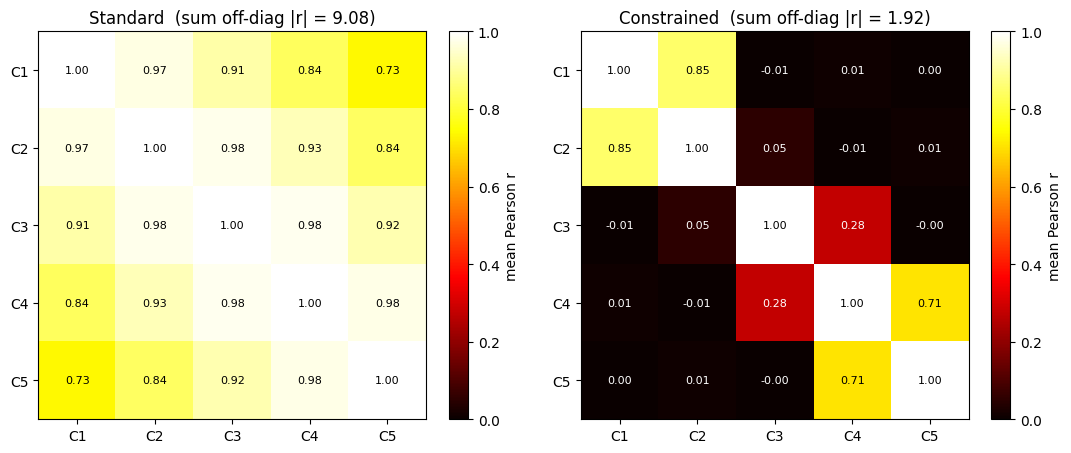

In [238]:
# ══════════════════════════════════════════════════════════════════════
#  Direction × direction hidden-state correlation matrices (mean over seeds)
# ══════════════════════════════════════════════════════════════════════

def _getC(s, c):
    """
    Retrieve collected test-set results for one seed and condition.

    Parameters
    ----------
    s : int
        Random seed identifying the trained model.
    c : str
        Model condition: "std" -> Standard, "con" -> Constrained.

    Returns
    -------
    dict
        Collected test-set results from collect().
    """
    if "cs" in globals() and c in cs and s == REF_SEED:
        return cs[c]
    return collect(load_model(s, c), test_loader, torch.device("cpu"))


def corr_matrix(C):
    """
    Direction-by-direction Pearson correlation matrix.

    Hidden activity is averaged across trials within each direction,
    then flattened across time and hidden units.

    Returns
    -------
    ndarray, shape (Num_Trajectories, Num_Trajectories)
    """
    H, dc = C["hid"], C["dir"]
    M = np.stack([H[:, dc == d, :].mean(axis=1).ravel()
                  for d in range(Num_Trajectories)])
    return np.corrcoef(M)


# Direction-indexed matrices are comparable across seeds because rows and
# columns correspond to task directions, not to individual hidden units.
mats = {c: np.mean([corr_matrix(_getC(s, c)) for s in CURVE_SEEDS], axis=0)
        for c in ("std", "con")}

# Unique off-diagonal entries — same aggregation as corr_penalty().
iu     = np.triu_indices(Num_Trajectories, k=1)
labels = [f"C{d + 1}" for d in range(Num_Trajectories)]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))

for a, (c, title) in zip(ax, [("std", "Standard"), ("con", "Constrained")]):
    M  = mats[c]
    im = a.imshow(M, cmap="hot", vmin=0, vmax=1)

    for i in range(Num_Trajectories):
        for j in range(Num_Trajectories):
            v = M[i, j]
            a.text(j, i, f"{v:.2f}",
                   ha="center", va="center",
                   color="k" if v > 0.5 else "w",
                   fontsize=8)

    a.set_xticks(range(Num_Trajectories))
    a.set_yticks(range(Num_Trajectories))
    a.set_xticklabels(labels)
    a.set_yticklabels(labels)

    sum_offdiag_abs_r = np.abs(M[iu]).sum()
    a.set_title(f"{title}  (sum off-diag |r| = {sum_offdiag_abs_r:.2f})")

    fig.colorbar(im, ax=a, fraction=0.046, label="mean Pearson r")

plt.tight_layout()
display(fig); plt.close(fig)

## Testing the Decorrelation Penalty

This analysis checks whether the constrained model reduces similarity between hidden-state representations of different movement directions.

For each seed, the hidden activity is averaged within each direction, and the absolute Pearson correlation is calculated for every direction pair. Panel 1 shows the distribution across pairs, while Panel 2 summarizes the median correlation for each seed.



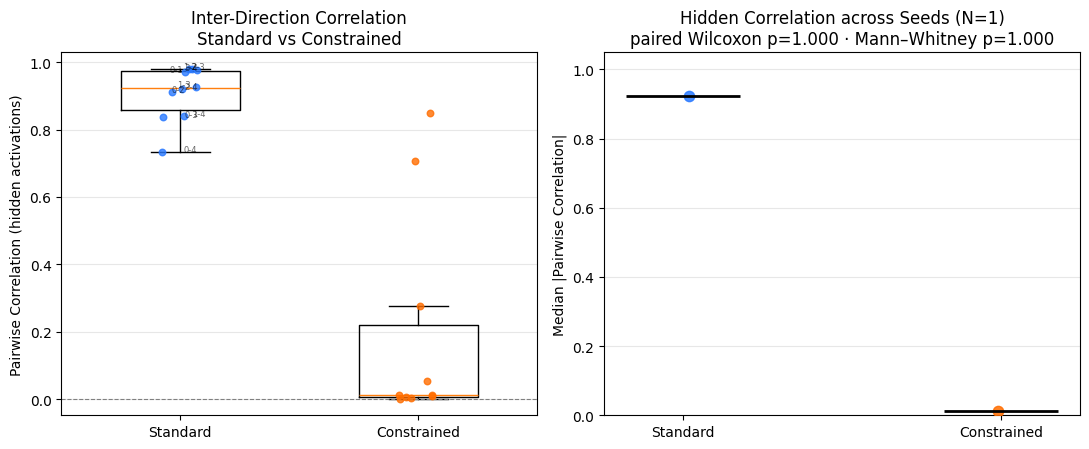

median |r|  std=0.924  con=0.011  | no overlap: min(std)=0.924 > max(con)=0.011
Cliff's delta = +1.00  (±1 = complete separation)
paired Wilcoxon p=1.0000  [floor 1.0000]   Mann–Whitney p=1.0000  [floor 1.0000]


In [ ]:
# ── Inter-direction correlation: Standard vs Constrained ──
# Within-model, cross-direction |r| — exactly what corr_penalty minimizes. 
from scipy.stats import wilcoxon, mannwhitneyu
from math import comb
iu  = np.triu_indices(Num_Trajectories, 1)
C_S = globals().get("C_STD", "#4C8BF5"); C_C = globals().get("C_CON", "#FF7F0E")

Mmat = {(s, c): corr_matrix(_getC(s, c)) for s in CURVE_SEEDS for c in ("std", "con")}
Rm   = {c: np.mean([Mmat[(s, c)] for s in CURVE_SEEDS], axis=0) for c in ("std", "con")}
pairsA = {c: np.abs(Rm[c][iu]) for c in ("std", "con")}                       # 28 dir-pairs
medB   = {c: np.array([np.median(np.abs(Mmat[(s, c)][iu])) for s in CURVE_SEEDS])
          for c in ("std", "con")}                                           # 1 per seed
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))

# Panel A — per-direction-pair cloud
for x, c in enumerate(("std", "con")):
    v = pairsA[c]; col = C_S if c == "std" else C_C
    ax[0].boxplot(v, positions=[x], widths=.5, showfliers=False)
    ax[0].scatter(np.full_like(v, x) + rng.uniform(-.08, .08, len(v)), v, color=col, s=22, alpha=.8, zorder=3)
for (i, j), y in zip(zip(*iu), pairsA["std"]):
    ax[0].annotate(f"{i}-{j}", (rng.uniform(-.05, .05), y), fontsize=6, alpha=.6)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Standard", "Constrained"])
ax[0].set_ylabel("Pairwise Correlation (hidden activations)")
ax[0].set_title("Inter-Direction Correlation\nStandard vs Constrained")
ax[0].axhline(0, ls="--", lw=.8, color="gray"); ax[0].grid(True, axis="y", alpha=.3)

# Panel B — per-seed median, both tests
for x, c in enumerate(("std", "con")):
    v = medB[c]; col = C_S if c == "std" else C_C
    ax[1].scatter(np.full_like(v, x) + rng.uniform(-.05, .05, len(v)), v, color=col, s=55, alpha=.85, zorder=3)
    ax[1].hlines(np.median(v), x - .18, x + .18, color="k", lw=2, zorder=4)
n = len(CURVE_SEEDS)
w_p = wilcoxon(medB["std"], medB["con"]).pvalue
u_p = mannwhitneyu(medB["std"], medB["con"], alternative="two-sided").pvalue
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Standard", "Constrained"]); ax[1].set_ylim(0, 1.05)
ax[1].set_ylabel("Median |Pairwise Correlation|"); ax[1].grid(True, axis="y", alpha=.3)
ax[1].set_title(f"Hidden Correlation across Seeds (N={n})\n"
                f"paired Wilcoxon p={w_p:.3f} · Mann–Whitney p={u_p:.3f}")
plt.tight_layout(); plt.show()

cliffs = np.mean([np.sign(a - b) for a in medB["std"] for b in medB["con"]])
print(f"median |r|  std={np.median(medB['std']):.3f}  con={np.median(medB['con']):.3f}  "
      f"| no overlap: min(std)={medB['std'].min():.3f} > max(con)={medB['con'].max():.3f}")
print(f"Cliff's delta = {cliffs:+.2f}  (±1 = complete separation)")
print(f"paired Wilcoxon p={w_p:.4f}  [floor {2/2**n:.4f}]   "
      f"Mann–Whitney p={u_p:.4f}  [floor {2/comb(2*n, n):.4f}]")

## Parameter Sweep and Hidden-State Metrics

This cell defines the parameter sweep used to compare the standard and constrained recurrent neural networks across task complexity and random initialisation.

The full experiment varies:

- The number of movement directions from 2 to 7.
- The angular spacing between adjacent directions from 10 deg to 30 deg.
- Ten independent random seeds.
- Two penalty conditions: alpha = 0 for the standard model and alpha = 1 for the constrained model.

Set `SMOKE = True` to run a small end-to-end pipeline check. The smoke configuration uses two direction counts, one angular spacing, two seeds, a reduced epoch , fewer trials, and a smaller hidden layer. These results are intended only to identify coding or caching errors and must not be used for scientific conclusions.

Set `SMOKE = False` for the full analysis after confirming that the pipeline runs correctly. The constrained penalty is fixed at alpha_con = 1 so that the results remain directly comparable with the alpha-0/1 sweep.

The analysis reports two complementary measurements of hidden activity:

1. `penalty_parts` computes the sum, mean, and median absolute correlations between direction-specific hidden-state responses.
2. `cis_fraction` estimates the fraction of direction-mean hidden-state power shared across directions, providing a measure of condition-independent activity.



In [ ]:
# ── sweep configuration ──────────────────────────────────────────────────
SMOKE = True   # << tiny/fast end-to-end check. 

N_DIRS_LIST    = [2, 3, 4, 5, 6, 7]
ANGLE_SPACINGS = [10, 20, 30]
SEEDS          = [42, 123, 456, 789, 987, 654, 321, 111, 222, 333]   # 10 seeds
ALPHAS         = [0.0, 1.0]           # 0.0 -> Standard/Control, 1.0 -> Constrained
ALPHA_CON      = 1.0
_COND_OF       = {0.0: "std", 1.0: "con"}
EPOCHS_GRID    = 12000                # headroom above the target figure's ~10000 ceiling
PATIENCE_GRID  = 300
TRIALS_PER_DIR = 256
SPLIT_SEED     = 42
NOISE_MODE     = "absolute"
TARGET_NOISE   = 0.171
assert ALPHA_CON == 1.0, "Constrained weight must be 1.0 to match the alpha01 sweep."

if SMOKE:                              # cheap smoke config — NOT scientifically meaningful
    N_DIRS_LIST    = [2, 3]
    ANGLE_SPACINGS = [20]
    SEEDS          = [42, 123]
    EPOCHS_GRID    = 8
    PATIENCE_GRID  = 4
    TRIALS_PER_DIR = 24
    globals()["N_H"] = 32              # shrink the model for speed
    print("SMOKE mode: tiny config, results are throwaway.")

# cache filenames carry the epoch budget so raising it can't reuse short-trained caches
SCALAR_CKPT = f"pern_epochs_alpha01_e{EPOCHS_GRID}.pkl"
print("SCALAR_CKPT =", SCALAR_CKPT, "| EPOCHS_GRID =", EPOCHS_GRID, "| N_H =", N_H)

# Fixed geometry (from your parameter block)
D1, D2   = 0, 10
TOTAL    = 100
N_HOLD_O = N_HOLD_T = int(TOTAL / 6)
N_ARC    = int(TOTAL * (0.1 * D2))
SIGMA    = 3
SCALE    = 1.0
AUG      = 12

def build_synth(n, ang, data_seed=0):
    """One (n_dirs, angle) dataset -> stim (N,T,3), targ (N,T,2), dirs (N,)."""
    total_deg = ang * (n - 1)
    max_absX  = D2 * np.sin(np.deg2rad(total_deg / 2)) if total_deg > 0 else 1.0
    nl = (TARGET_NOISE / max_absX) if NOISE_MODE == "absolute" else 0.05

    inp, out, _ = generate_diverging_trajectories(
        num_trajectories=n, total_angle_deg=total_deg, d1=D1, d2=D2,
        n_hold_origin=N_HOLD_O, n_hold_target=N_HOLD_T,
        n_straight=int(TOTAL * (0.1 * D1)), n_arc=N_ARC,
        augmentation_factor=AUG, noise_level=nl, plot=False,
        scale=SCALE, sigma=SIGMA, random_seed=42 + data_seed)

    d_ids = np.rint(inp[:, 0] / SCALE).astype(np.int64)
    T     = out.shape[1]

    rng  = np.random.default_rng(0)
    keep = np.concatenate([rng.choice(np.where(d_ids == d)[0], TRIALS_PER_DIR,
                                      replace=False) for d in range(n)])
    rng.shuffle(keep)
    out, d_ids = out[keep], d_ids[keep]

    tpl   = np.stack([out[d_ids == d][:1].mean(0) for d in range(n)])
    theta = np.arctan2(tpl[:, -1, 1], tpl[:, -1, 0])

    stim = np.zeros((len(out), T, 3), dtype=np.float32)
    stim[:, :N_HOLD_O, 0] = 2.0 * 0.1                       
    stim[:, :, 1] = (2.0 * np.cos(theta))[d_ids][:, None]
    stim[:, :, 2] = (2.0 * np.sin(theta))[d_ids][:, None]
    return stim, out.astype(np.float32), d_ids, np.rad2deg(theta), N_HOLD_O

def penalty_parts(hid, dirs):
    """Returns (sum|r|, mean|r|, median|r|) over direction pairs — numpy (measurement)."""
    ds = np.unique(dirs)
    M  = np.array([hid[:, dirs == d, :].mean(1).ravel() for d in ds])
    C  = np.corrcoef(M); i, j = np.triu_indices(len(ds), k=1)
    v  = np.abs(C[i, j])
    return v.sum(), v.mean(), np.median(v)

def cis_fraction(hid, dirs):
    """Share of direction-mean power in the condition-independent signal."""
    M = np.stack([hid[:, dirs == d, :].mean(1) for d in np.unique(dirs)])
    return float((M.mean(0, keepdims=True) ** 2).sum() / (M ** 2).sum())

SMOKE mode: tiny config, results are throwaway.
SCALAR_CKPT = pern_epochs_alpha01_e8.pkl | EPOCHS_GRID = 8 | N_H = 32


## Training and Cache Engine

This cell trains the standard and constrained recurrent-network models for each requested combination of angular spacing and random seed, then caches both the held-out hidden activity and scalar summary statistics.

The validation criterion is **MSE only** for both model conditions. The constrained model includes the correlation penalty during training, but the penalty is excluded from validation-based checkpoint selection so that early stopping compares predictive performance fairly between the standard and constrained models.

For every run, the model state corresponding to the lowest validation MSE is restored before test evaluation. The following training metadata are recorded:

- `best_epoch`: one-based epoch at which the lowest validation MSE was observed.
- `stop_epoch`: one-based epoch at which training ended.
- `epoch_censored`: whether training reached the epoch budget without patience-based early stopping.
- `epochs_budget`: maximum number of training epochs available.

The cache filenames include the epoch budget and hidden-layer size. The scalar checkpoint stores predictive performance, hidden-state correlation measures, condition-independent activity, and training metadata. Existing results are reused only when both the scalar entry and the corresponding hidden-state cache file are present.

Smoke-mode results are intended only to verify that data generation, training, evaluation, and caching work end to end. They must not be used for scientific interpretation.


In [ ]:
# ── engine: train_and_cache with epoch recording (best_epoch = epochs to best val MSE) ──
import pickle, os, time
import numpy as np, torch

for _v in ["build_synth","make_loaders","RNN","collect","mse_loss","corr_penalty",
           "to_device","DEV","LR","CLIP","N_IN","N_H","EPOCHS_GRID","PATIENCE_GRID",
           "SPLIT_SEED","ALPHA_CON","ALPHAS","_COND_OF","penalty_parts","cis_fraction"]:
    assert _v in globals(), f"{_v} missing — run the Setup cells above first."

def _f(n, ang, seed, cond):
    return f"hid_{n}_{ang}_{seed}_{cond}_a{ALPHA_CON}_e{EPOCHS_GRID}.npz"   

def train_and_cache(n, seeds=None, angles=None):
    seeds  = SEEDS if seeds is None else seeds
    angles = ANGLE_SPACINGS if angles is None else angles
    scal = pickle.load(open(SCALAR_CKPT,"rb")) if os.path.exists(SCALAR_CKPT) else {}
    todo = [(ang,seed) for ang in angles for seed in seeds
            if any(((n,ang,seed,_COND_OF[a]) not in scal
                    or not os.path.exists(_f(n,ang,seed,_COND_OF[a]))) for a in ALPHAS)]
    print(f"n={n}: {len(seeds)*len(angles)} cells | {len(todo)} to train "
          f"({2*len(todo)} runs) | {len(seeds)*len(angles)-len(todo)} cached")
    t0=time.time()
    for ci,(ang,seed) in enumerate(todo,1):
        stim,targ,dirs,theta_g,go = build_synth(n,ang)
        globals()["T0_LOSS"]=go
        tr,va,te,te_idx = make_loaders(stim,targ,dirs,seed=SPLIT_SEED)
        dte = dirs[te_idx]
        for alpha in ALPHAS:
            cond=_COND_OF[alpha]; use_pen=alpha>0.0
            if (n,ang,seed,cond) in scal and os.path.exists(_f(n,ang,seed,cond)):
                continue
            m = RNN(N_IN,N_H,2,seed=seed).to(DEV)
            opt = torch.optim.Adam(m.parameters(), lr=LR)
            best,wait,state = float("inf"),0,None
            best_ep = 0                                              
            for ep in range(EPOCHS_GRID):
                m.train()
                for X,Y,D in tr:
                    X,Y=to_device(X,Y,DEV); D=D.to(DEV); opt.zero_grad()
                    o,h=m(X)
                    loss = mse_loss(o,Y) + (ALPHA_CON*corr_penalty(h,D) if use_pen else 0)
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(m.parameters(),CLIP); opt.step()
                vl = collect(m,va,DEV)["loss"]        # MSE-only on val (fair criterion)
                if vl < best-1e-6:
                    best,wait = vl,0
                    best_ep = ep                                    
                    state = {k:v.cpu().clone() for k,v in m.state_dict().items()}
                else:
                    wait += 1
                if wait>=PATIENCE_GRID: break
            stop_ep  = ep                                           
            censored = (stop_ep >= EPOCHS_GRID-1)                   
            if state is not None: m.load_state_dict(state)
            r = collect(m,te,DEV)
            np.savez_compressed(_f(n,ang,seed,cond),
                hid=r["hid"].astype(np.float16), out=r["out"], tgt=r["tgt"],
                dirs_te=dte, theta_deg=theta_g, go=go, alpha=float(alpha))
            p_sum,p_mean,p_med = penalty_parts(r["hid"],dte)
            o_,t_ = r["out"].transpose(1,0,2), r["tgt"].transpose(1,0,2)
            mse_pd = {int(d):float(((o_[dte==d,go:]-t_[dte==d,go:])**2).mean()) for d in np.unique(dte)}
            scal[(n,ang,seed,cond)] = dict(alpha=float(alpha), abs_r=float(p_med),
                abs_r_mean=float(p_mean), pen_sum=float(p_sum),
                mse_mean=float(np.mean(list(mse_pd.values()))),
                mse_worst=float(max(mse_pd.values())), val=float(best),
                cis_frac=cis_fraction(r["hid"],dte), n_pairs=n*(n-1)//2,
                best_epoch=int(best_ep), stop_epoch=int(stop_ep),      # [NEW]
                epoch_censored=bool(censored), epochs_budget=int(EPOCHS_GRID))  # [NEW]
            pickle.dump(scal, open(SCALAR_CKPT,"wb"))
        el=(time.time()-t0)/60
        print(f"  [{ci}/{len(todo)}] ang={ang} seed={seed}  {el:.0f} min, "
              f"~{el/ci*(len(todo)-ci):.0f} min left")
    print(f"n={n} done — {(time.time()-t0)/60:.0f} min")

In [ ]:
for n in N_DIRS_LIST:
    train_and_cache(n)

n=2: 30 cells | 30 to train (60 runs) | 0 cached
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [1/30] ang=10 seed=42  7 min, ~214 min left
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [2/30] ang=10 seed=123  14 min, ~194 min left
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [3/30] ang=10 seed=456  21 min, ~193 min left
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [4/30] ang=10 seed=789  26 min, ~171 min left
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [5/30] ang=10 seed=987  31 min, ~157 min left
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [6/30] ang=10 seed=654  37 min, ~149 min left
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [7/30] ang=10 seed=321  45 min, ~147 min left
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [8/30] ang=10 seed=111  50 min, ~138 min left
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [9/30] ang=10 seed=222  57 min, ~133 min left
INPUTS  : (8192, 1)
OUTPUTS : (8192, 132, 2)
  [10/30] ang=10 seed=333  64 min, ~127 min left
INPUTS  : (8192, 1)
OU

## Epoch Distribution Across Conditions

This cell visualizes the number of epochs required to reach the best validation MSE for the control and constrained models at one fixed angular spacing.

For each trajectory count K, the plot combines:

- Boxplots showing the distribution of `best_epoch` across random seeds.
- Individual points showing the value for each seed.
- Light connecting lines matching the same seed across the two conditions.
- A separate color for the control and constrained models.
- An annotation identifying runs whose training was right-censored by the epoch budget.

The analysis uses `best_epoch` as the primary quantity because it records when the best validation checkpoint occurred. The `stop_epoch` value is intentionally not plotted here; it only indicates when training terminated and may reflect patience-based early stopping rather than the epoch of optimal validation performance.

Only one angular spacing is plotted, selected through `PLOT_ANGLE`, because pooling across angles would mix an additional within-seed experimental factor. If any runs reach the epoch ceiling, increase `EPOCHS_GRID` and rerun the training sweep before interpreting the epoch distributions.

When `SMOKE=True`, the figure is labeled as a throwaway diagnostic and should be used only to verify that the plotting and cache-reading logic work correctly.


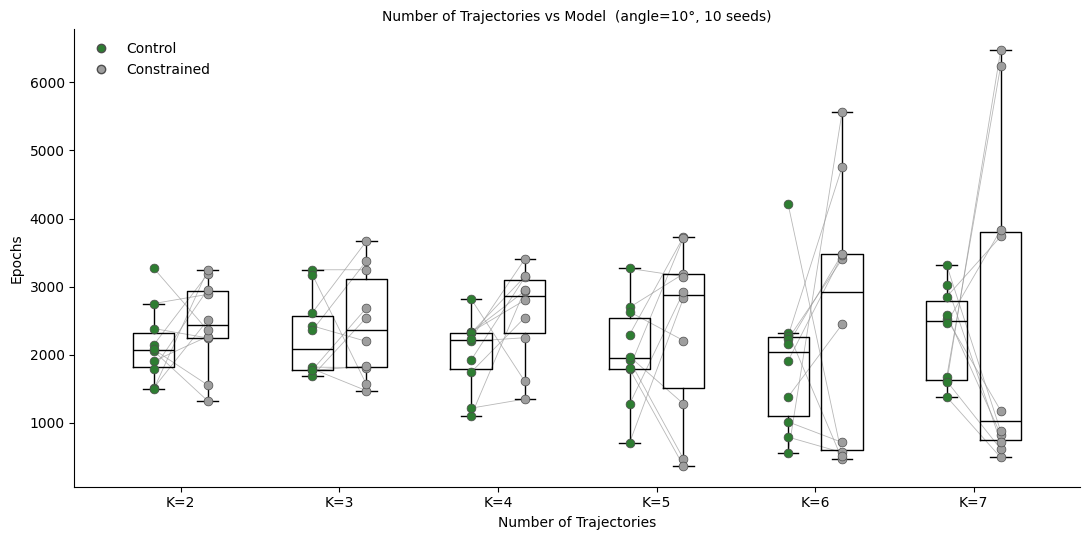

In [ ]:
import numpy as np, pickle
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

PLOT_ANGLE = ANGLE_SPACINGS[0]     
KS         = list(N_DIRS_LIST)
EPOCH_KEY  = "best_epoch"         
COND_COL   = {"std": "#2e7d32", "con": "#9e9e9e"}  

scal = pickle.load(open(SCALAR_CKPT, "rb"))

def _epochs(n, cond):
    vals, cens = [], []
    for s in SEEDS:
        row = scal.get((n, PLOT_ANGLE, s, cond))
        if row is None or EPOCH_KEY not in row:  continue
        vals.append(row[EPOCH_KEY]); cens.append(bool(row.get("epoch_censored", False)))
    return np.array(vals, float), np.array(cens, bool)

fig, ax = plt.subplots(figsize=(11, 5.5))
gap, box_w = 0.34, 0.26
xt, n_cens = [], 0
for i, n in enumerate(KS):
    xc = i + 1; xt.append(xc)
    es, cs = _epochs(n, "std"); ec, cc = _epochs(n, "con")
    n_cens += int(cs.sum() + cc.sum())
    for k in range(min(len(es), len(ec))):                       # seed-matched lines
        ax.plot([xc-gap/2, xc+gap/2], [es[k], ec[k]], color="0.6", lw=0.6, alpha=0.7, zorder=1)
    for cond, xoff, v in [("std", -gap/2, es), ("con", +gap/2, ec)]:
        if len(v) == 0:  continue
        ax.boxplot(v, positions=[xc+xoff], widths=box_w, showfliers=False,
                   medianprops=dict(color="k"))
        ax.scatter(np.full(len(v), xc+xoff), v, s=40, facecolor=COND_COL[cond],
                   edgecolor="0.3", lw=0.5, zorder=3)
ax.set_xticks(xt); ax.set_xticklabels([f"K={k}" for k in KS])
ax.set_xlabel("Number of Trajectories"); ax.set_ylabel("Epochs")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.legend(handles=[Line2D([0],[0], marker="o", ls="", markerfacecolor=COND_COL["std"],
                          markeredgecolor="0.3", label="Control"),
                   Line2D([0],[0], marker="o", ls="", markerfacecolor=COND_COL["con"],
                          markeredgecolor="0.3", label="Constrained")],
          loc="upper left", frameon=False)
ttl = "Number of Trajectories vs Model" if globals().get("SMOKE") else "Epochs to best val"
ax.set_title(f"{ttl}  (angle={PLOT_ANGLE}\u00b0, {len(SEEDS)} seeds)", fontsize=10)
if n_cens:
    ax.text(0.99, 0.02, f"! {n_cens} seed(s) hit the {EPOCHS_GRID}-epoch ceiling "
            f"(right-censored) — raise EPOCHS_GRID and re-run.",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=7, color="firebrick")
plt.tight_layout(); plt.show()

## Epochs to Loss Threshold

This cell calculates how many epochs each model needs to reach several common validation-loss thresholds.

For every seed, model, and threshold, it records the first epoch at which:

Only thresholds reached by all runs are retained, ensuring a fair comparison between the Standard and Constrained models. The resulting epochs-to-threshold data are summarized across seeds and used in the subsequent repeated-measures ANOVA.


In [ ]:
# ══════════════════════════════════════════════════════════════════════
#  Multi-seed training — Std/Con pairs, matched init, full per-epoch traces.
#  Matched init: both models in a pair share a seed,the ONLY difference is the penalty.
#  Resumable: caches full traces to loss_curves_plateau.pkl — same cache file
# ══════════════════════════════════════════════════════════════════════
import pickle, os, time

DEV          = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ALPHA, LR    = 1, 1e-3
CLIP         = 0.2
CURVE_SEEDS  = [42, 123, 456, 777, 999, 2023, 31415, 271828,
                7, 13, 88, 101, 202, 303, 404, 505, 606, 707, 808, 909]   # 20 seeds
MAX_EPOCHS   = 1000
PRINT_EVERY  = 1
CKPT         = "loss_curves_plateau.pkl"

for _v in ["RNN", "mse_loss", "corr_penalty", "collect", "to_device",
           "train_loader", "val_loader", "test_loader", "N_IN"]:
    if _v not in globals():
        raise NameError(f"{_v} missing — run the cells above first.")

curves = pickle.load(open(CKPT, "rb")) if os.path.exists(CKPT) else {}
print(f"{len(curves)}/{2*len(CURVE_SEEDS)} traces cached  |  DEV={DEV}  MAX_EPOCHS={MAX_EPOCHS}")

def train_run(seed, use_pen, tag="", t0=None):
    m   = RNN(N_IN, 300, 2, seed=seed).to(DEV)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    log = {"tr": [], "val": [], "pen": []}          # tr=MSE, pen=sum|r| (logged for BOTH)
    for ep in range(MAX_EPOCHS):
        m.train(); tr = pen = nb = 0
        for X, Y, D in train_loader:
            X, Y = to_device(X, Y, DEV); D = D.to(DEV)
            opt.zero_grad()
            o, h = m(X)
            l = mse_loss(o, Y)
            p = corr_penalty(h, D)
            (l + ALPHA * p if use_pen else l).backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), CLIP)
            opt.step()
            tr += l.item(); pen += p.item(); nb += 1
        vl = collect(m, val_loader, DEV)["loss"]
        log["tr"].append(tr / nb); log["pen"].append(pen / nb); log["val"].append(vl)
        if ep % PRINT_EVERY == 0 or ep == MAX_EPOCHS - 1:
            el = f"  [{(time.time()-t0)/60:.1f} min]" if t0 is not None else ""
            print(f"    {tag}  ep {ep+1:4d}/{MAX_EPOCHS}   "
                  f"MSE {tr/nb:.5f}   val {vl:.5f}   sum|r| {pen/nb:7.3f}{el}")
    log["test"] = collect(m, test_loader, DEV)["loss"]
    return log

t0 = time.time()
for seed in CURVE_SEEDS:
    for cond, use_pen in [("std", False), ("con", True)]:
        if (seed, cond) in curves:
            print(f"  seed {seed} {cond}: cached, skipping")
            continue
        print(f"\n=== training seed {seed}  {cond}  (use_pen={use_pen}) ===")
        curves[(seed, cond)] = train_run(seed, use_pen, tag=f"s{seed} {cond}", t0=t0)
        pickle.dump(curves, open(CKPT, "wb"))
        print(f"  -> seed {seed} {cond} DONE: final val {curves[(seed, cond)]['val'][-1]:.5f}  "
              f"sum|r| {curves[(seed, cond)]['pen'][-1]:.3f}  [{(time.time()-t0)/60:.1f} min]")
print(f"\ndone — {len(curves)} traces in {(time.time()-t0)/60:.1f} min")

40/40 traces cached  |  DEV=cpu  MAX_EPOCHS=1000
  seed 42 std: cached, skipping
  seed 42 con: cached, skipping
  seed 123 std: cached, skipping
  seed 123 con: cached, skipping
  seed 456 std: cached, skipping
  seed 456 con: cached, skipping
  seed 777 std: cached, skipping
  seed 777 con: cached, skipping
  seed 999 std: cached, skipping
  seed 999 con: cached, skipping
  seed 2023 std: cached, skipping
  seed 2023 con: cached, skipping
  seed 31415 std: cached, skipping
  seed 31415 con: cached, skipping
  seed 271828 std: cached, skipping
  seed 271828 con: cached, skipping
  seed 7 std: cached, skipping
  seed 7 con: cached, skipping
  seed 13 std: cached, skipping
  seed 13 con: cached, skipping
  seed 88 std: cached, skipping
  seed 88 con: cached, skipping
  seed 101 std: cached, skipping
  seed 101 con: cached, skipping
  seed 202 std: cached, skipping
  seed 202 con: cached, skipping
  seed 303 std: cached, skipping
  seed 303 con: cached, skipping
  seed 404 std: cached, s

In [ ]:
# ── Data hygiene check: flag any cached run shorter than MAX_EPOCHS ────────.
short = {k: len(v["val"]) for k, v in curves.items() if len(v["val"]) < MAX_EPOCHS}
if short:
    print(f"!! {len(short)} cached run(s) shorter than MAX_EPOCHS={MAX_EPOCHS}:")
    for (seed, cond), n in sorted(short.items()):
        print(f"   seed {seed:>6} {cond:4s}  ->  {n} epochs cached")
    print("   -> delete these keys from the pickle and rerun the training cell to extend them.")
else:
    print(f"all {len(curves)} cached runs reach the full MAX_EPOCHS={MAX_EPOCHS}.")

!! 6 cached run(s) shorter than MAX_EPOCHS=1000:
   seed     42 con   ->  400 epochs cached
   seed     42 std   ->  400 epochs cached
   seed    123 con   ->  400 epochs cached
   seed    123 std   ->  400 epochs cached
   seed    456 con   ->  400 epochs cached
   seed    456 std   ->  400 epochs cached
   -> delete these keys from the pickle and rerun the training cell to extend them.


In [147]:
# ══════════════════════════════════════════════════════════════════════
#  Coarse epochs-to-threshold extraction — feeds the RM-ANOVA (next cell).
#  Self-contained: reads `curves` (loss_curves_plateau.pkl).
#  DV = first epoch (1-indexed) at which SIGNAL first dips <= threshold.
# ══════════════════════════════════════════════════════════════════════
import pickle, os, numpy as np, pandas as pd

if "curves" not in globals():
    curves = pickle.load(open("loss_curves_plateau.pkl", "rb"))

SIGNAL   = "val"
LAB      = {"std": "Standard", "con": "Constrained"}   # swap to "Control" here if aligning with Ousama's labels
seeds    = sorted({s for (s, _) in curves})
print(f"{len(seeds)} seeds x 2 models = {len(curves)} runs   |   SIGNAL={SIGNAL}")

def first_crossing(curve, L):
    """1-indexed epoch of the first dip <= L; None if never reached."""
    idx = np.where(np.asarray(curve, float) <= L)[0]
    return int(idx[0] + 1) if idx.size else None

floors = {k: float(np.min(v[SIGNAL])) for k, v in curves.items()}
ceils  = {k: float(np.max(v[SIGNAL])) for k, v in curves.items()}
floor_max = max(floors.values())       # tightest loss EVERY run reaches  -> lower bound
ceil_min  = min(ceils.values())        # highest loss EVERY run starts above -> upper bound

print(f"binding floor across all runs (floor_max) : {floor_max:.5f}")
print(f"common ceiling across all runs (ceil_min)  : {ceil_min:.5f}")

N_LEVELS = 6
MARGIN   = 0.05       # keep the tightest level 5% above the binding floor
lo = floor_max * (1 + MARGIN)
hi = ceil_min
if lo >= hi:
    raise ValueError(f"empty reachable band: floor_max*(1+MARGIN)={lo:.4f} >= ceil_min={hi:.4f}. "
                     "One model barely learns; widen MAX_EPOCHS or lower MARGIN.")
LEVELS = np.array(sorted(map(float, np.geomspace(hi, lo, N_LEVELS)), reverse=True))

recs = []
for (s, c), v in curves.items():
    for L in LEVELS:
        recs.append(dict(seed=s, model=LAB[c], level=float(L),
                         epochs=first_crossing(v[SIGNAL], L)))
E = pd.DataFrame(recs)

unreachable = sorted(E.loc[E.epochs.isna(), "level"].unique(), reverse=True)
if unreachable:
    print(f"\n!! dropping {len(unreachable)} censored level(s) not reached by every run: "
          f"{[float(round(x,4)) for x in unreachable]}")
    E = E[~E.level.isin(unreachable)].copy()
LEVELS_USED = sorted(E.level.unique(), reverse=True)
print(f"\n{len(LEVELS_USED)} thresholds in the reachable band: {[float(round(x,4)) for x in LEVELS_USED]}")

piv = (E.groupby(["model", "level"])["epochs"]
         .agg(["mean", "std"]).reset_index()
         .sort_values(["model", "level"], ascending=[True, False]))
print("\nepochs-to-threshold (mean +/- sd across seeds):")
for m in ("Standard", "Constrained"):
    sub = piv[piv.model == m]
    line = "  ".join(f"L{L:.3f}:{r['mean']:.0f}+/-{(r['std'] if not np.isnan(r['std']) else 0):.0f}"
                      for L, r in zip(sub.level, sub.to_dict("records")))
    print(f"  {m:12s} {line}")

20 seeds x 2 models = 40 runs   |   SIGNAL=val
binding floor across all runs (floor_max) : 0.01624
common ceiling across all runs (ceil_min)  : 0.23174

6 thresholds in the reachable band: [0.2317, 0.1375, 0.0816, 0.0484, 0.0287, 0.0171]

epochs-to-threshold (mean +/- sd across seeds):
  Standard     L0.232:2+/-1  L0.138:3+/-1  L0.082:5+/-2  L0.048:8+/-3  L0.029:19+/-5  L0.017:102+/-22
  Constrained  L0.232:8+/-2  L0.138:14+/-3  L0.082:24+/-7  L0.048:41+/-10  L0.029:72+/-12  L0.017:277+/-55


In [ ]:
# ══════════════════════════════════════════════════════════════════════
#  2-way RM-ANOVA (Model x Loss) + per-level Bonferroni post-hocs.
#  Subject = seed. Both factors within-subject (matched inits, all coarse
#  levels measured on every run). Reads `E` from the cell above.
# ══════════════════════════════════════════════════════════════════════
import numpy as np, pandas as pd, pingouin as pg
from scipy import stats

LOG_EPOCHS = True        

Ea = E.dropna(subset=["epochs"]).copy()
Ea["y"] = np.log(Ea["epochs"]) if LOG_EPOCHS else Ea["epochs"].astype(float)
Ea["level"] = Ea["level"].round(4).astype(str)     

n_seed = Ea["seed"].nunique()
print(f"N = {n_seed} seeds   |   DV = {'log(epochs)' if LOG_EPOCHS else 'epochs'}   "
      f"|   levels = {Ea['level'].nunique()}\n")

sk = stats.skew(Ea["y"])
print(f"DV skewness = {sk:+.2f}   (|skew|>1 -> consider LOG_EPOCHS=True or a nonparametric check)\n")

aov = pg.rm_anova(data=Ea, dv="y", within=["model", "level"], subject="seed",
                  detailed=True, effsize="np2")
aov = aov.rename(columns={"p-unc": "p_unc", "p-GG-corr": "p_GG_corr"})
show = [c for c in ["Source", "F", "p_unc", "p_GG_corr", "np2"] if c in aov.columns]
print("2-way RM-ANOVA:")
print(aov[show].to_string(index=False))
print("\n  -> read the Model and model*level rows. The Loss main effect is a nuisance "
      "(lower loss always takes longer).")

levs = sorted(Ea["level"].unique(), key=float, reverse=True)
rows = []
for L in levs:
    d = Ea[Ea.level == L]
    a = d[d.model == "Standard"].set_index("seed")["y"]
    b = d[d.model == "Constrained"].set_index("seed")["y"]
    idx = a.index.intersection(b.index)
    a, b = a.loc[idx], b.loc[idx]
    t, p = stats.ttest_rel(b, a)                 # Constrained - Standard
    rows.append(dict(level=float(L), n=len(idx),
                     epochs_std=float(a.mean()), epochs_con=float(b.mean()),
                     delta=float((b - a).mean()), t=float(t), p=float(p)))
post = pd.DataFrame(rows)
post["p_bonf"] = np.minimum(post["p"] * len(post), 1.0)
print("\nper-level paired contrast (Constrained - Standard), Bonferroni across levels:")
with pd.option_context("display.float_format", lambda x: f"{x:.4g}"):
    print(post.to_string(index=False))

if n_seed < 8:
    print(f"\n!! N = {n_seed} seeds is underpowered for this design. Treat p-values as "
          "provisional until the full ~20-seed run is in.")

N = 20 seeds   |   DV = log(epochs)   |   levels = 6

DV skewness = +0.28   (|skew|>1 -> consider LOG_EPOCHS=True or a nonparametric check)

2-way RM-ANOVA:
       Source           F        p_unc    p_GG_corr      np2
        model 1033.901861 4.964788e-18 4.964788e-18 0.981955
        level 1174.477663 9.776681e-84 3.539946e-56 0.984080
model * level   10.212409 7.494307e-08 3.456214e-06 0.349591

  -> read the Model and model*level rows. The Loss main effect is a nuisance (lower loss always takes longer).

per-level paired contrast (Constrained - Standard), Bonferroni across levels:
 level  n  epochs_std  epochs_con  delta     t         p    p_bonf
0.2317 20      0.8057       2.026  1.221 12.64 1.074e-10 6.445e-10
0.1375 20       1.025       2.608  1.582 21.42  9.13e-15 5.478e-14
0.0816 20       1.583       3.137  1.554 15.05 5.173e-12 3.104e-11
0.0484 20       2.039       3.686  1.648 21.72 7.096e-15 4.258e-14
0.0287 20       2.923       4.257  1.334 17.27 4.501e-13 2.701e-12
0.0171

/Users/kevin/work/hiwi/lib/python3.9/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/Users/kevin/work/hiwi/lib/python3.9/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  data.groupby(level=1, axis=1, observed=True, group_keys=False)


In [ ]:
# ══════════════════════════════════════════════════════════════════════
#  Fine linear grid 
# ══════════════════════════════════════════════════════════════════════
import numpy as np, pandas as pd

N_LEVELS_FINE = 40
LEVELS_FINE = np.linspace(hi, lo, N_LEVELS_FINE)     

recs_fine = []
for (s, c), v in curves.items():
    for L in LEVELS_FINE:
        recs_fine.append(dict(seed=s, model=LAB[c], level=float(L),
                              epochs=first_crossing(v[SIGNAL], L)))
E_fine = pd.DataFrame(recs_fine)
censored_fine = E_fine.loc[E_fine.epochs.isna(), "level"].unique()
if len(censored_fine):
    print(f"dropping {len(censored_fine)} fine level(s) not reached by every run")
    E_fine = E_fine[~E_fine.level.isin(censored_fine)].copy()
print(f"{E_fine.level.nunique()} fine thresholds retained for the figure")

40 fine thresholds retained for the figure


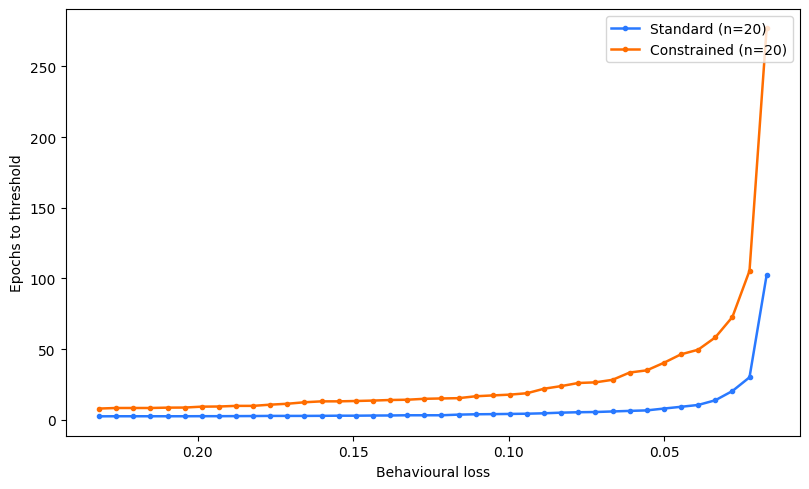

saved -> ./Fig 5 --- Behavioral Loss (MSE) wrt Epochs --- ( Standard vs Constrained ).svg


In [ ]:
# ── Figure: epochs-to-threshold ─────────────────────
import matplotlib.pyplot as plt, os

FOLDER = "."   # set to your results folder
FIGURE = r'Fig 5 --- Behavioral Loss (MSE) wrt Epochs --- ( Standard vs Constrained ).svg'
PATH = os.path.join(FOLDER, FIGURE)

fig, ax = plt.subplots(figsize=(8.2, 5))
for m, c in [("Standard", "#2979ff"), ("Constrained", "#ff6d00")]:
    sub = E_fine[E_fine.model == m]
    g = sub.groupby("level")["epochs"].mean().reset_index().sort_values("level", ascending=False)
    ax.plot(g.level, g.epochs, color=c, lw=1.8, marker="o", ms=3,
            label=f"{m} (n={sub.seed.nunique()})")

ax.invert_xaxis()                                    # tighter threshold to the right
ax.set_xlabel("Behavioural loss")
ax.set_ylabel("Epochs to threshold")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(PATH, format="svg")
plt.show()
print(f"saved -> {PATH}")

## Penalty-to-MSE Dominance Check

This cell compares the constrained-model correlation penalty with its trajectory MSE during the final training epochs. The ratio indicates how strongly the penalty contributes relative to the prediction error.

A ratio above 1 means the weighted penalty is larger than the MSE. The median ratio across the final 50 epochs summarizes whether the penalty dominates the constrained model’s objective.


In [ ]:
ALPHA = 1.0
rows = []
for (seed, cond), v in curves.items():
    if cond != 'con':
        continue
    tr  = np.array(v['tr'])          # MSE per epoch
    pen = np.array(v['pen'])         # sum|r| per epoch
    ratio = (ALPHA * pen) / np.maximum(tr, 1e-12)
    rows.append(dict(seed=seed, mse_final=tr[-1], pen_final=pen[-1],
                     alpha_pen_final=ALPHA*pen[-1], ratio_final=ratio[-1],
                     ratio_mean_last50=ratio[-50:].mean()))
dom = pd.DataFrame(rows).sort_values('seed')
print(dom.to_string(index=False))
print(f"\nmedian ratio (ALPHA*pen / MSE) over last 50 epochs: {dom.ratio_mean_last50.median():.2f}x")

  seed  mse_final  pen_final  alpha_pen_final  ratio_final  ratio_mean_last50
     7   0.015565   0.020406         0.020406     1.310969           1.297047
    13   0.015945   0.021277         0.021277     1.334462           1.288892
    42   0.017643   0.044578         0.044578     2.526628           2.370024
    88   0.015606   0.019218         0.019218     1.231483           1.302580
   101   0.016086   0.027327         0.027327     1.698789           1.661553
   123   0.018312   0.041009         0.041009     2.239388           2.409148
   202   0.015768   0.020537         0.020537     1.302491           1.419517
   303   0.016545   0.032860         0.032860     1.986064           1.909316
   404   0.016264   0.030974         0.030974     1.904413           1.785966
   456   0.017337   0.038796         0.038796     2.237771           2.299972
   505   0.016584   0.026455         0.026455     1.595249           1.582124
   606   0.016591   0.029380         0.029380     1.770838      

In [ ]:
# ── Which runs set the reachable band?-────────────────────────────
import numpy as np, pandas as pd
SIGNAL = globals().get("SIGNAL", "val")
MAX_EPOCHS_H = globals().get("MAX_EPOCHS", 1000)

rows = [dict(seed=s, cond=c, n_epochs=len(v[SIGNAL]),
             floor=float(np.min(v[SIGNAL])), ceil=float(np.max(v[SIGNAL])),
             short=len(v[SIGNAL]) < MAX_EPOCHS_H)
        for (s, c), v in curves.items()]
F = pd.DataFrame(rows)
binding = F.loc[F.floor.idxmax()]
print("runs with the highest floors (these fix the tightest reachable ϑ):")
print(F.sort_values("floor", ascending=False).head(6).to_string(index=False,
      float_format=lambda x: f"{x:.5f}"))
print(f"\nbinding floor_max = {binding.floor:.5f}  <- seed {binding.seed} {binding.cond}"
      f"  ({binding.n_epochs} epochs cached, short={bool(binding.short)})")

full = F[~F.short]
if len(full) and F.short.any():
    print(f"\nfloor_max over FULL-LENGTH runs only : {full.floor.max():.5f} "
          f"(seed {full.loc[full.floor.idxmax(),'seed']} {full.loc[full.floor.idxmax(),'cond']})")
    print(f"floor_max including truncated runs   : {F.floor.max():.5f}")
    print(f"-> retraining 42/123/456 would move the tightest ϑ by "
          f"{100*(F.floor.max()/full.floor.max()-1):+.1f}%")
print(f"\nshort runs among the 6 highest floors: "
      f"{int(F.sort_values('floor', ascending=False).head(6).short.sum())}/6")

runs with the highest floors (these fix the tightest reachable ϑ):
 seed cond  n_epochs   floor    ceil  short
   42  con       400 0.01624 0.80561   True
  456  con       400 0.01624 1.21159   True
  123  con       400 0.01607 0.65287   True
  303  con      1000 0.01558 0.81264  False
31415  con      1000 0.01554 0.89936  False
  606  con      1000 0.01554 0.84791  False

binding floor_max = 0.01624  <- seed 42 con  (400 epochs cached, short=True)

floor_max over FULL-LENGTH runs only : 0.01558 (seed 303 con)
floor_max including truncated runs   : 0.01624
-> retraining 42/123/456 would move the tightest ϑ by +4.3%

short runs among the 6 highest floors: 3/6


## Paired Tests Across Loss Thresholds

This cell tests whether Standard and Constrained models differ in the number of epochs needed to reach a range of validation-loss thresholds.

For each threshold, paired t-tests compare matched seeds using log-transformed epochs. P-values are Bonferroni-corrected across all fine thresholds.

The plot shows adjusted significance as log_10p; values above the dashed line indicate p < 0.05. The results table reports the mean epochs, test statistics, raw p-values, and adjusted p-values for each threshold.


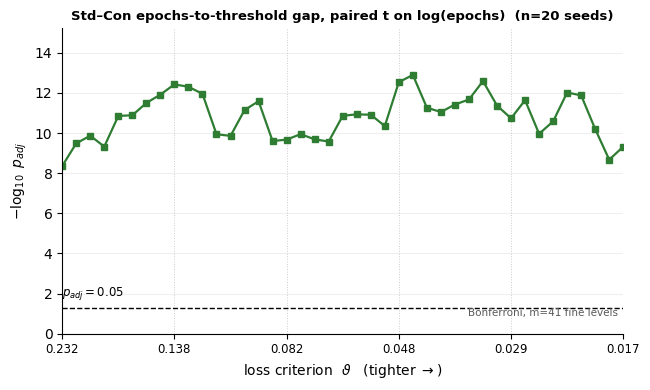

  level  n  ep_std  ep_con     t         p    p_bonf
 0.2317 20   2.238   7.585 12.64 1.074e-10 4.404e-09
 0.2171 20   2.317   8.013 14.69 7.923e-12 3.249e-10
 0.2034 20   2.317   8.421 15.44 3.308e-12 1.356e-10
 0.1906 20   2.399   9.198 14.38 1.156e-11 4.739e-10
 0.1785 20   2.448   10.26 17.54 3.419e-13 1.402e-11
 0.1673 20   2.534   11.41 17.61 3.171e-13   1.3e-11
 0.1567 20   2.586   12.57 19.05  7.73e-14 3.169e-12
 0.1468 20   2.732   12.84 20.08 2.958e-14 1.213e-12
 0.1375 20   2.788   13.57 21.42  9.13e-15 3.744e-13
 0.1288 20   2.919   14.42  21.1 1.204e-14 4.938e-13
 0.1207 20   2.919   14.64 20.18 2.702e-14 1.108e-12
 0.1131 20   3.589   16.06 15.59 2.783e-12 1.141e-10
 0.1059 20   3.641   16.57 15.42 3.383e-12 1.387e-10
0.09925 20   3.867   17.13  18.2 1.749e-13  7.17e-12
0.09299 20   4.268   18.13 19.26 6.306e-14 2.585e-12
0.08711 20   4.469   21.24 14.91 6.121e-12  2.51e-10
0.08161 20   4.871   23.03 15.05 5.173e-12 2.121e-10
0.07646 20   4.975   25.35  15.6  2.76e-12 1.1

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import ttest_rel

SIGNAL = globals().get("SIGNAL", "val")
LAB    = globals().get("LAB", {"std": "Standard", "con": "Constrained"})
LOG_EPOCHS_H = globals().get("LOG_EPOCHS", True)     # mirror cell 16's DV
N_LEVELS_FINE_H = 41                                  # 40 steps / 5 => coarse nests

if "first_crossing" not in globals():
    def first_crossing(curve, L):
        idx = np.where(np.asarray(curve, float) <= L)[0]
        return int(idx[0] + 1) if idx.size else None

_floors = {k: float(np.min(v[SIGNAL])) for k, v in curves.items()}
_ceils  = {k: float(np.max(v[SIGNAL])) for k, v in curves.items()}
hi_H = globals().get("hi", min(_ceils.values()))
lo_H = globals().get("lo", max(_floors.values()) * 1.05)
LEVELS_FINE_H = np.geomspace(hi_H, lo_H, N_LEVELS_FINE_H)   # was np.linspace

E_H = pd.DataFrame([dict(seed=s, model=LAB[c], level=float(L),
                         epochs=first_crossing(v[SIGNAL], L))
                    for (s, c), v in curves.items() for L in LEVELS_FINE_H])
_cens = E_H.loc[E_H.epochs.isna(), "level"].unique()
if len(_cens):
    print(f"dropping {len(_cens)} censored fine level(s) not reached by every run")
    E_H = E_H[~E_H.level.isin(_cens)].copy()
E_H["y"] = np.log(E_H.epochs.astype(float)) if LOG_EPOCHS_H else E_H.epochs.astype(float)

rows = []
for L in sorted(E_H.level.unique(), reverse=True):
    d = E_H[E_H.level == L]
    a = d[d.model == "Standard"].set_index("seed")["y"]
    b = d[d.model == "Constrained"].set_index("seed")["y"]
    idx = a.index.intersection(b.index)
    if len(idx) < 3 or not np.any((b.loc[idx] - a.loc[idx]).to_numpy()):
        continue
    tstat, p = ttest_rel(b.loc[idx], a.loc[idx])          # Constrained - Standard
    rows.append(dict(level=float(L), n=len(idx), t=float(tstat), p=float(p),
                     ep_std=float(np.exp(a.loc[idx].mean())),   # geometric means,
                     ep_con=float(np.exp(b.loc[idx].mean()))))  # matching the log DV
H = pd.DataFrame(rows)
M_FINE = len(H)
H["p_bonf"] = np.minimum(H["p"] * M_FINE, 1.0)

# ── figure ────────────────────────────────────────────────────────────────────
COARSE = np.asarray(globals().get("LEVELS", []), float)
fig, ax = plt.subplots(figsize=(6.6, 4.0))

for L in COARSE:
    ax.axvline(L, color="0.8", lw=0.7, ls=":", zorder=0)
ax.plot(H.level, -np.log10(H.p_bonf), color="#2e7d32", marker="s", ms=4, lw=1.6)
ax.axhline(-np.log10(0.05), ls="--", color="k", lw=1.0)
ax.text(H.level.max(), -np.log10(0.05) + 0.3, r"$p_{adj}=0.05$", fontsize=8.5, va="bottom")

ax.set_xscale("log")
ax.set_xlim(H.level.max(), H.level.min())      # inverted: loose left, tight right
ax.set_ylim(0, float((-np.log10(H.p_bonf)).max()) * 1.18)
if COARSE.size:
    ax.set_xticks(COARSE)
    ax.set_xticklabels([f"{L:.3f}" for L in COARSE], fontsize=8.5)
ax.minorticks_off()
ax.set_xlabel(r"loss criterion  $\vartheta$   (tighter $\rightarrow$)")
ax.set_ylabel(r"$-\log_{10}\ p_{adj}$")
ax.set_title(f"Std–Con epochs-to-threshold gap, paired t on log(epochs)  "
             f"(n={int(H.n.max())} seeds)", fontsize=9.5, fontweight="bold")
ax.text(0.99, 0.05, f"Bonferroni, m={M_FINE} fine levels"
                    ,
        transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5, color="0.35")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
display(fig); plt.close(fig)

print(H[["level", "n", "ep_std", "ep_con", "t", "p", "p_bonf"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"\nϑ range: {H.level.max():.4f} -> {H.level.min():.4f}  "
      f"({M_FINE} levels, n constant = {int(H.n.min())})")
print(f"all p_adj < 0.05: {bool((H.p_bonf < 0.05).all())}   "
      f"weakest level: ϑ={H.loc[H.p_bonf.idxmax(),'level']:.4f}, p_adj={H.p_bonf.max():.3g}")
# cross-check against cell 16: coarse levels are a subset of this grid
if COARSE.size:
    _chk = H[np.isclose(H.level.values[:, None], COARSE[None, :], rtol=1e-9).any(1)]
    print(f"\ncoarse levels recovered on the fine grid: {len(_chk)}/{len(COARSE)} "
          f"(should be {len(COARSE)}; compare p to cell 16's p column, not p_bonf — "
          f"different m)")
    print(_chk[["level", "ep_std", "ep_con", "t", "p"]]
          .to_string(index=False, float_format=lambda x: f"{x:.4g}"))